# Лабораторная работа № 2 — задание 1

Выполняли Свешников Борис — ИСУ 467394 и Хасанов Дмитрий — ИСУ 467920.

## Условие и вычисление варианта

Номер варианта равен сумме ИСУ-идентификаторов по модулю 6 плюс 1:

$$467394+467920=935314,\qquad 935314\bmod 6+1=4+1=5.$$

**Вариант 5.** Методом моментов найти оценку параметра $\theta>0$ распределения с плотностью

$$p_\theta(t)=\theta t^{\theta-1}\mathbb{1}(t\in(0,1)).$$

Нужно найти смещение, дисперсию (или асимптотическую дисперсию), среднеквадратическую ошибку и обосновать свойства оценки. Затем для массива объёмов выборки требуется провести многократное моделирование, посчитать выборочные характеристики ошибки между оценкой и истинным параметром, число превышений заданного порога и визуализировать результаты.

In [1]:
import numpy as np
from IPython.display import Image, display

from plots.moment_estimation import (
    save_beta_density_plot,
    save_bias_comparison_plot,
    save_estimate_distributions_plot,
    save_estimator_benchmark_plot,
    save_mse_comparison_plot,
    save_threshold_exceedance_plot,
    save_variance_comparison_plot,
)
from utils.moment_estimation import run_monte_carlo_experiment

RANDOM_SEED = 24422442
THETA = 2.0
SMALL_N = np.linspace(10, 100, 19, dtype=int)
BIG_N = np.linspace(100, 10**4, 19, dtype=int)
VERY_BIG_N = np.linspace(10**5, 10**6, 11, dtype=int)
N = [SMALL_N, BIG_N, VERY_BIG_N]
M = 50
ERROR_THRESHOLD = 0.1
threshold = THETA * ERROR_THRESHOLD

isu = (467394, 467920)
variant = sum(isu) % 6 + 1

variant

5

### Параметры вычислительного эксперимента

Используем три шкалы объёмов выборки:

Для каждого $n$ генерируем $M=50$ независимых выборок. Для каждой выборки вычисляем оценку $\widehat\theta$ и разность $\widehat\theta-\theta.$

Существенной считаем относительную ошибку больше $10\%$:

$$\frac{|\widehat\theta-\theta|}{\theta}>0.1.$$

При $\theta=2$ абсолютный порог равен $\varepsilon=0.2$, а допустимый интервал имеет вид $[1.8,2.2]$. Порог визуализируем только на малой шкале `SMALL_N`, где отдельные оценки ещё достаточно различаются.

## Распределение

Сначала проверим, что заданная функция является плотностью. При $\theta>0$ она неотрицательна и

$$\int_{-\infty}^{\infty}p_\theta(t)\,dt
=\int_0^1\theta t^{\theta-1}\,dt
=\left[t^\theta\right]_0^1=1$$

Воспользуемся подсказкой и посмотрим на плотность бета-распределения:

$$p_{\alpha,\beta}(t)
=\frac{1}{B(\alpha,\beta)}t^{\alpha-1}(1-t)^{\beta-1}
\mathbb{1}(t\in(0,1))$$

При $\alpha=\theta$ и $\beta=1$

$$B(\theta,1)
=\frac{\Gamma(\theta)\Gamma(1)}{\Gamma(\theta+1)}
=\frac{\Gamma(\theta)}{\theta*\Gamma(\theta)}
=\frac1\theta$$

поэтому это и есть плотность нашего распределения в задаче. 

$$p_{\theta,1}(t)=\theta t^{\theta-1}\mathbb{1}(t\in(0,1))=p_\theta(t)$$

$$X\sim\operatorname{Beta}(\theta,1)$$

Выбрали $\theta = 2$, чтобы формула плотности была простой, но не тривиальной - $p_\theta(t) = 2t\mathbb{1}(t\in(0,1))$.

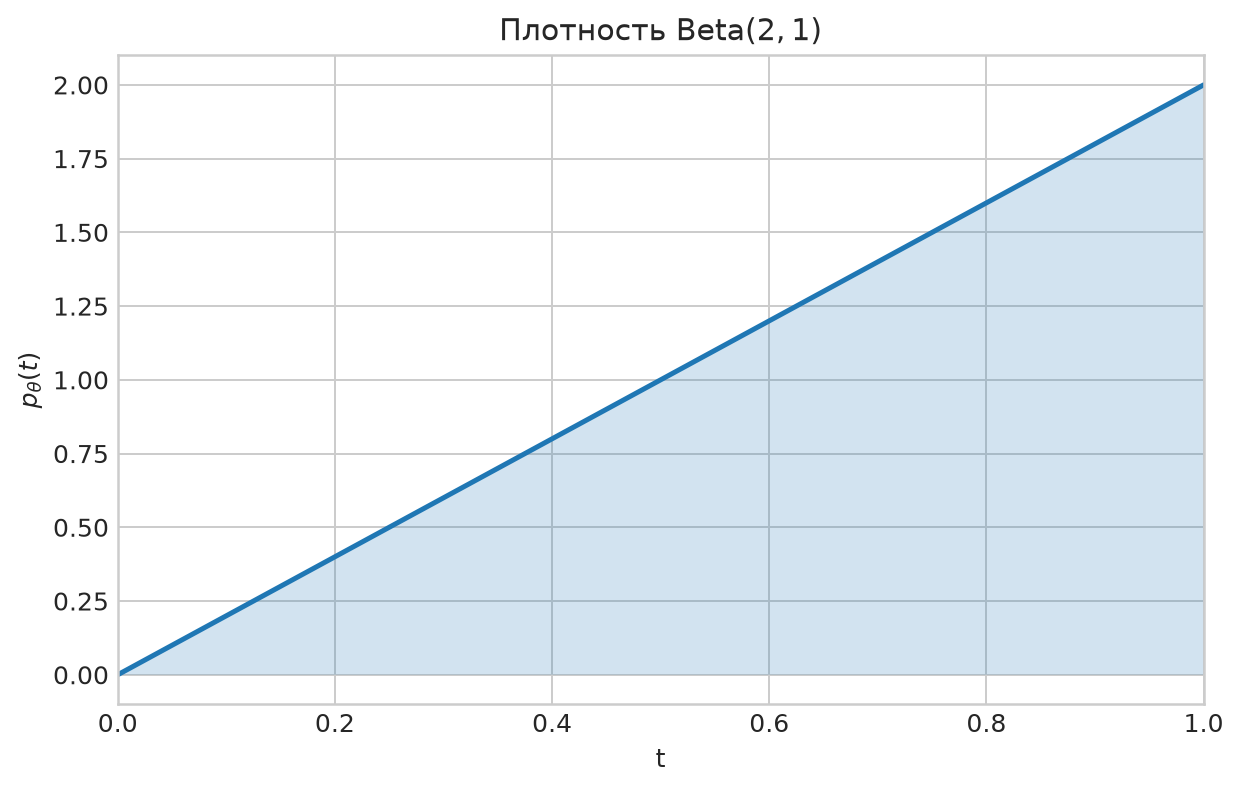

In [2]:
density_image = save_beta_density_plot(THETA)
display(Image(filename=str(density_image)))

## Оценка методом моментов

Сначала найдём теоретический первый момент одного наблюдения:

$$\mathbb E X
=\int_0^1t\,p_\theta(t)\,dt
=\int_0^1t\theta t^{\theta-1}\,dt
=\theta\int_0^1t^\theta\,dt
=\frac{\theta}{\theta+1}.$$

В методе моментов приравниваем его к выборочному среднему:

$$\overline X=\frac{\widehat\theta}{\widehat\theta+1}.$$

Решаем уравнение относительно $\widehat\theta$:

$$\overline X(\widehat\theta+1)=\widehat\theta,$$

$$\overline X=\widehat\theta(1-\overline X),$$

$$\boxed{\widehat\theta=\frac{\overline X}{1-\overline X}}.$$

Для каждой сгенерированной выборки сначала вычисляется $\overline X$, а после получается отдельная оценка $\widehat\theta$.

Отклонение среднего по выборкам от истинного параметра θ = 2:
n =      10: Δ = +0.233466
n =      15: Δ = +0.021835
n =      20: Δ = +0.057201
n =      25: Δ = -0.031555
n =      30: Δ = +0.117469
n =      35: Δ = +0.028341
n =      40: Δ = +0.084679
n =      45: Δ = -0.005021
n =      50: Δ = +0.000375
n =      55: Δ = +0.027514
n =      60: Δ = +0.072296
n =      65: Δ = +0.047702
n =      70: Δ = +0.063499
n =      75: Δ = +0.015360
n =      80: Δ = -0.031035
n =      85: Δ = +0.026721
n =      90: Δ = +0.018345
n =      95: Δ = +0.001373
n =     100: Δ = +0.035489


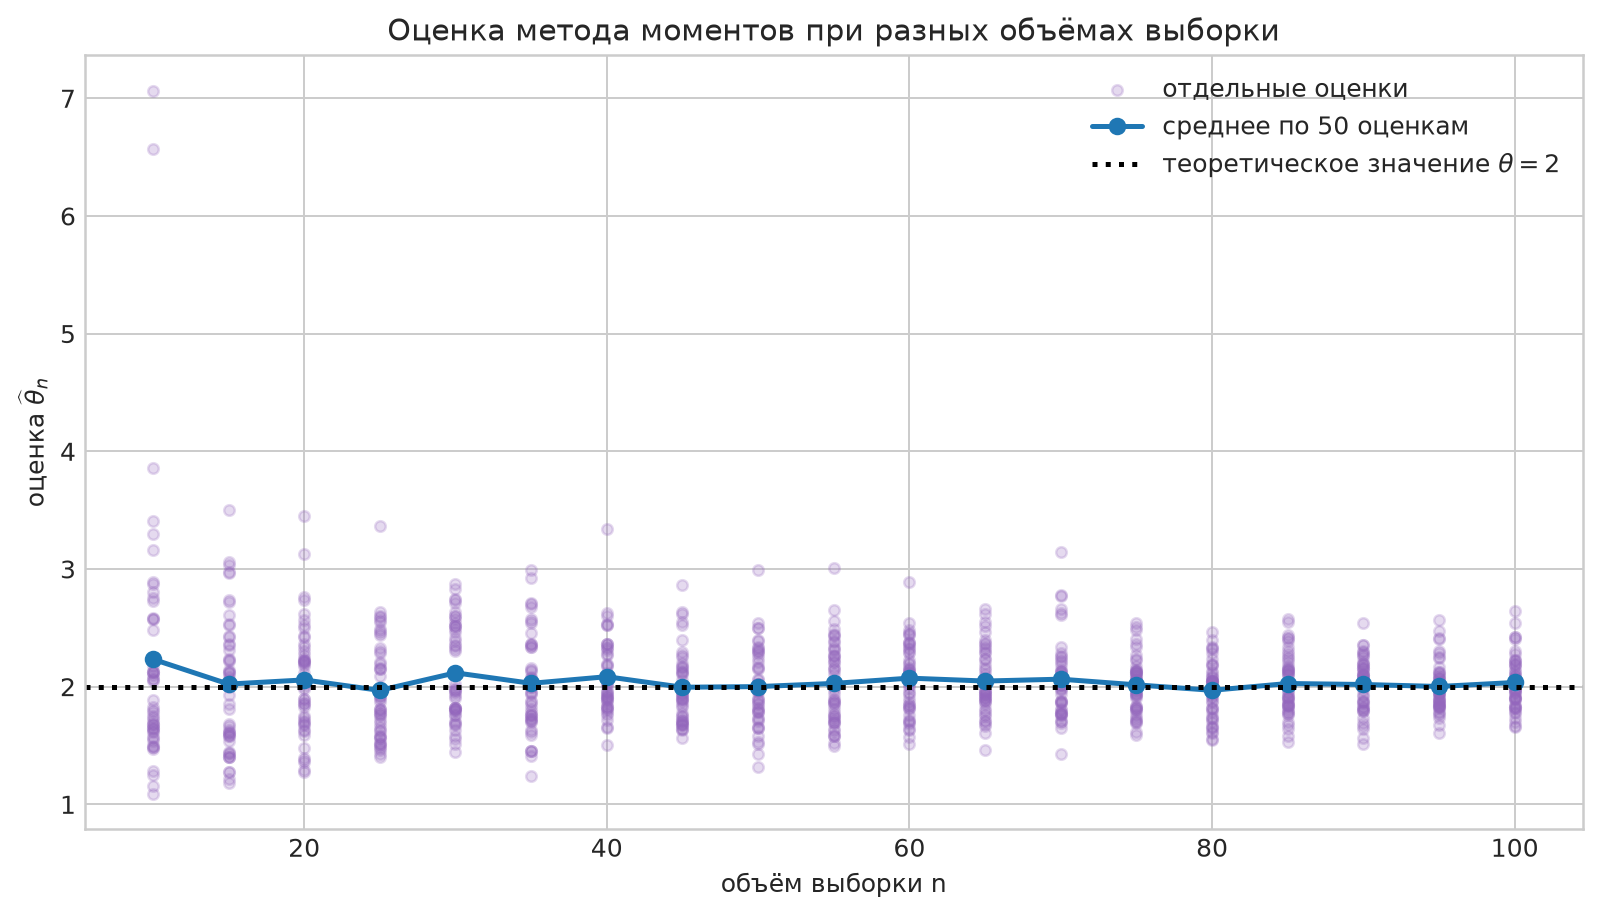

Отклонение среднего по выборкам от истинного параметра θ = 2:
n =     100: Δ = +0.005070
n =     650: Δ = +0.002961
n =    1200: Δ = -0.003578
n =    1750: Δ = -0.005299
n =    2300: Δ = -0.007138
n =    2850: Δ = -0.000677
n =    3400: Δ = -0.008405
n =    3950: Δ = -0.001720
n =    4500: Δ = -0.003406
n =    5050: Δ = +0.002679
n =    5600: Δ = -0.000762
n =    6150: Δ = +0.002425
n =    6700: Δ = -0.003912
n =    7250: Δ = -0.002786
n =    7800: Δ = +0.002186
n =    8350: Δ = -0.002334
n =    8900: Δ = -0.002326
n =    9450: Δ = +0.005806
n =   10000: Δ = -0.001465


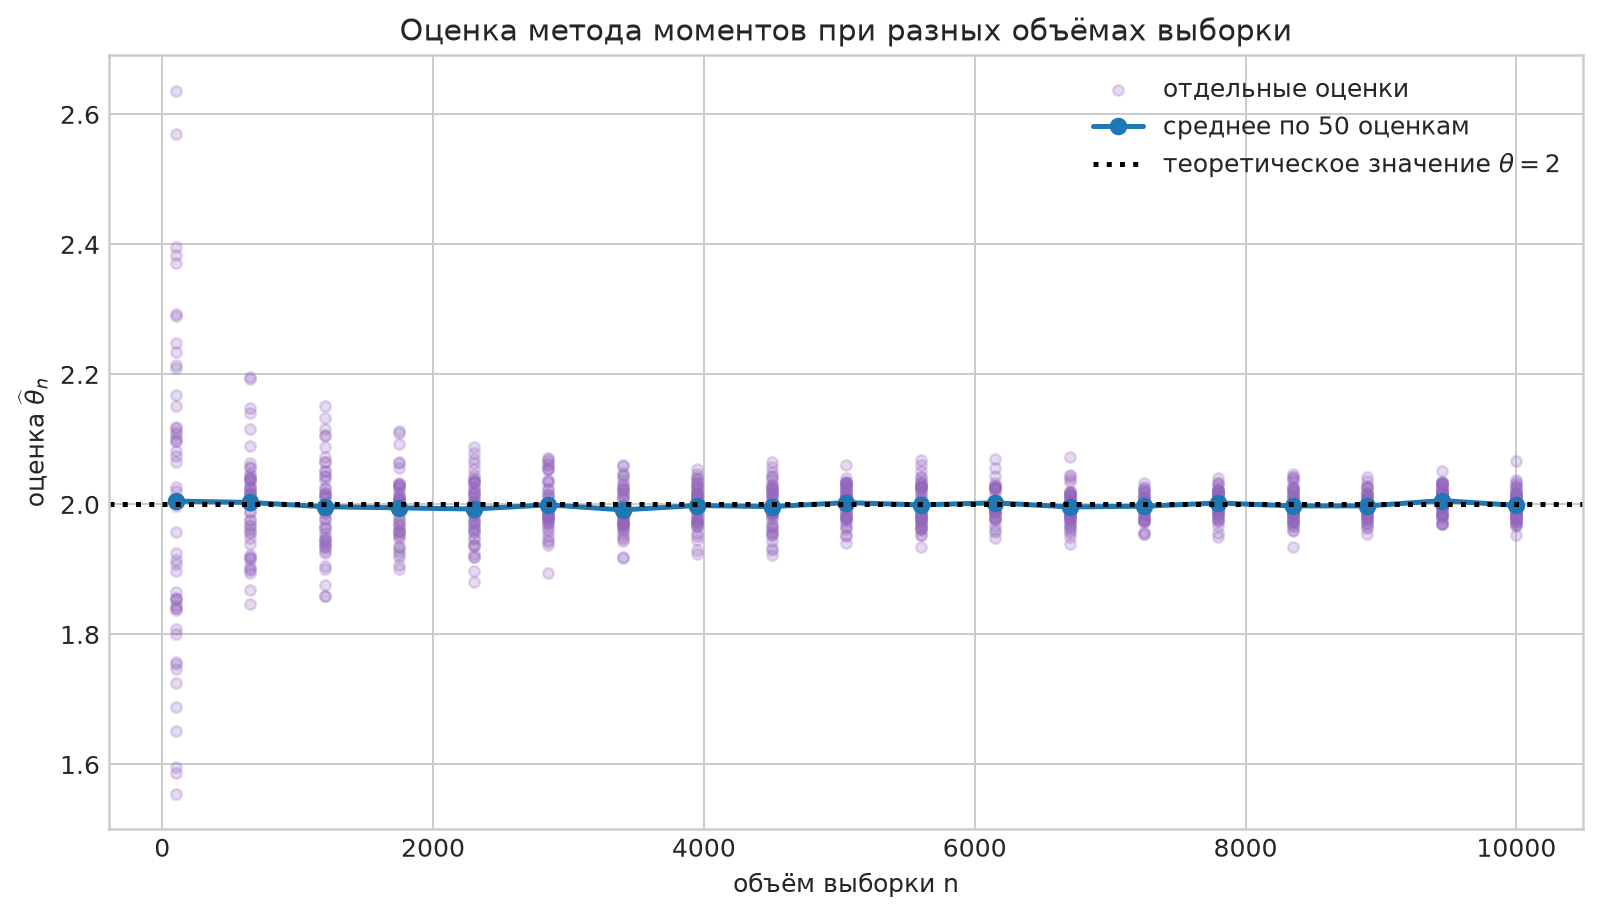

Отклонение среднего по выборкам от истинного параметра θ = 2:
n =  100000: Δ = -0.001320
n =  190000: Δ = -0.000931
n =  280000: Δ = +0.000554
n =  370000: Δ = -0.001019
n =  460000: Δ = -0.000061
n =  550000: Δ = +0.000489
n =  640000: Δ = -0.000060
n =  730000: Δ = -0.000309
n =  820000: Δ = +0.000821
n =  910000: Δ = +0.000199
n = 1000000: Δ = -0.000293


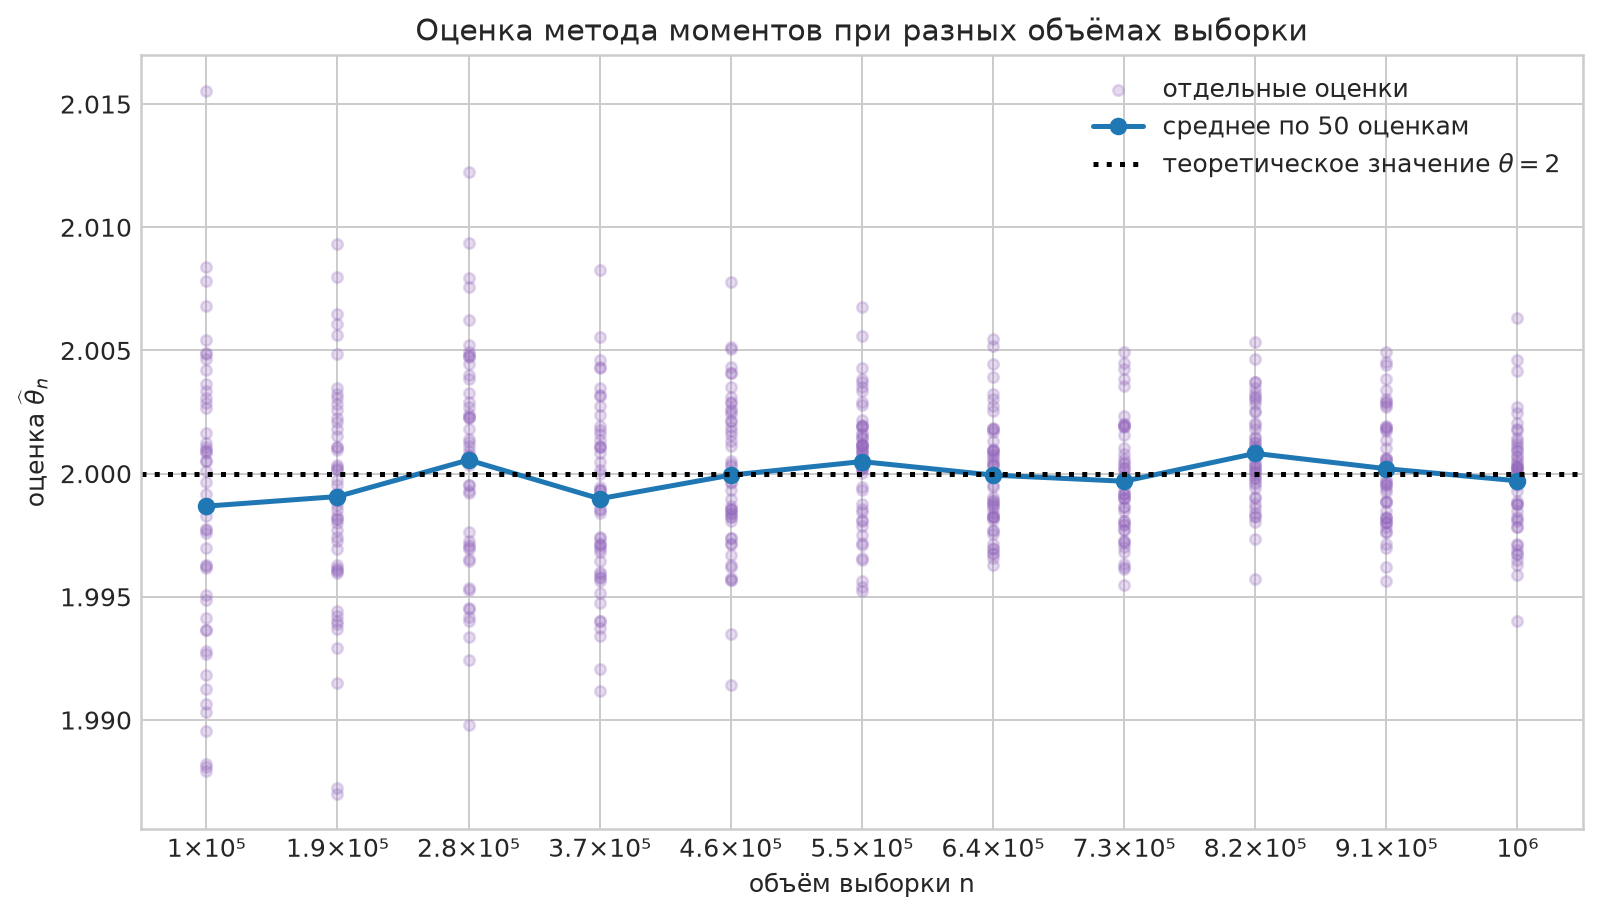

In [3]:
experiments = [
    run_monte_carlo_experiment(
        THETA,
        sizes,
        M,
        threshold,
        RANDOM_SEED,
    )
    for sizes in N
]

for sizes, experiment in zip(N, experiments):
    print(
        "Отклонение среднего по выборкам от истинного параметра θ = 2:"
    )
    for n in sizes:
        mean_estimate = experiment.estimates[int(n)].mean()
        expected_estimate = THETA
        delta = mean_estimate - expected_estimate
        print(f"n = {n:7d}: Δ = {delta:+.6f}")

    benchmark_image = save_estimator_benchmark_plot(experiment)
    display(Image(filename=str(benchmark_image)))

#### Вывод

С ростом $n$ отдельные оценки концентрируются около истинного значения $\theta=2$, а их среднее приближается к прямой $y=2$. 

## Смещение оценки

### 1. Выборочная величина

Для каждой отдельной оценки введём её отклонение от истинного параметра:

$$D_n^{(r)}=\widehat\theta_n^{(r)}-\theta,
\qquad r=1,\ldots,M.$$

Выборочное смещение — среднее этих отклонений:

$$\boxed{
\widehat{\operatorname{Bias}}_n
=\overline D_n
=\frac1M\sum_{r=1}^{M}
\left(\widehat\theta_n^{(r)}-\theta\right)
}.$$

На графике синяя линия показывает выборочное смещение, а оранжевая — его точное теоретическое значение.

### 2. Точное теоретическое значение

Положим $Y_i=1-X_i$ и $T_n=\sum_{i=1}^nY_i$. Тогда

$$\widehat\theta_n=\frac n{T_n}-1.$$

Для $Y_i\sim\operatorname{Beta}(1,\theta)$ преобразование Лапласа равно

$$\psi_\theta(s)
=\mathbb E_\theta e^{-sY_i}
={}_1F_1(1;\theta+1;-s).$$

Используем точное тождество

$$z^{-q}=\frac1{\Gamma(q)}
\int_0^\infty s^{q-1}e^{-sz}\,ds.$$

Из независимости $Y_1,\ldots,Y_n$ получаем обратные моменты суммы

$$I_q(n,\theta)=\mathbb E_\theta T_n^{-q}
=\frac1{\Gamma(q)}\int_0^\infty
s^{q-1}\psi_\theta(s)^n\,ds.$$

Для устойчивого численного вычисления делаем замену $s=u/n$ и обозначаем

$$A_q(n,\theta)=n^qI_q(n,\theta)
=\frac1{\Gamma(q)}\int_0^\infty
u^{q-1}\psi_\theta\left(\frac un\right)^n\,du.$$

Тогда

$$\mathbb E_\theta\widehat\theta_n=A_1(n,\theta)-1,$$

и точное смещение равно

$$\boxed{
\operatorname{Bias}_\theta(\widehat\theta_n)
=A_1(n,\theta)-1-\theta
}.$$

Интеграл вычисляется численно для каждого $n$; это точная теоретическая формула с погрешностью только численного интегрирования. Перед графиком выводится разность выборочного и точного теоретического смещений.

Отклонение выборочного смещения от точного теоретического:
n =      10: Δ = +0.064449
n =      15: Δ = -0.086208
n =      20: Δ = -0.022216
n =      25: Δ = -0.094343
n =      30: Δ = +0.065551
n =      35: Δ = -0.015916
n =      40: Δ = +0.046113
n =      45: Δ = -0.039194
n =      50: Δ = -0.030303
n =      55: Δ = -0.000318
n =      60: Δ = +0.046827
n =      65: Δ = +0.024227
n =      70: Δ = +0.041727
n =      75: Δ = -0.004939
n =      80: Δ = -0.050047
n =      85: Δ = +0.008842
n =      90: Δ = +0.001472
n =      95: Δ = -0.014602
n =     100: Δ = +0.020322


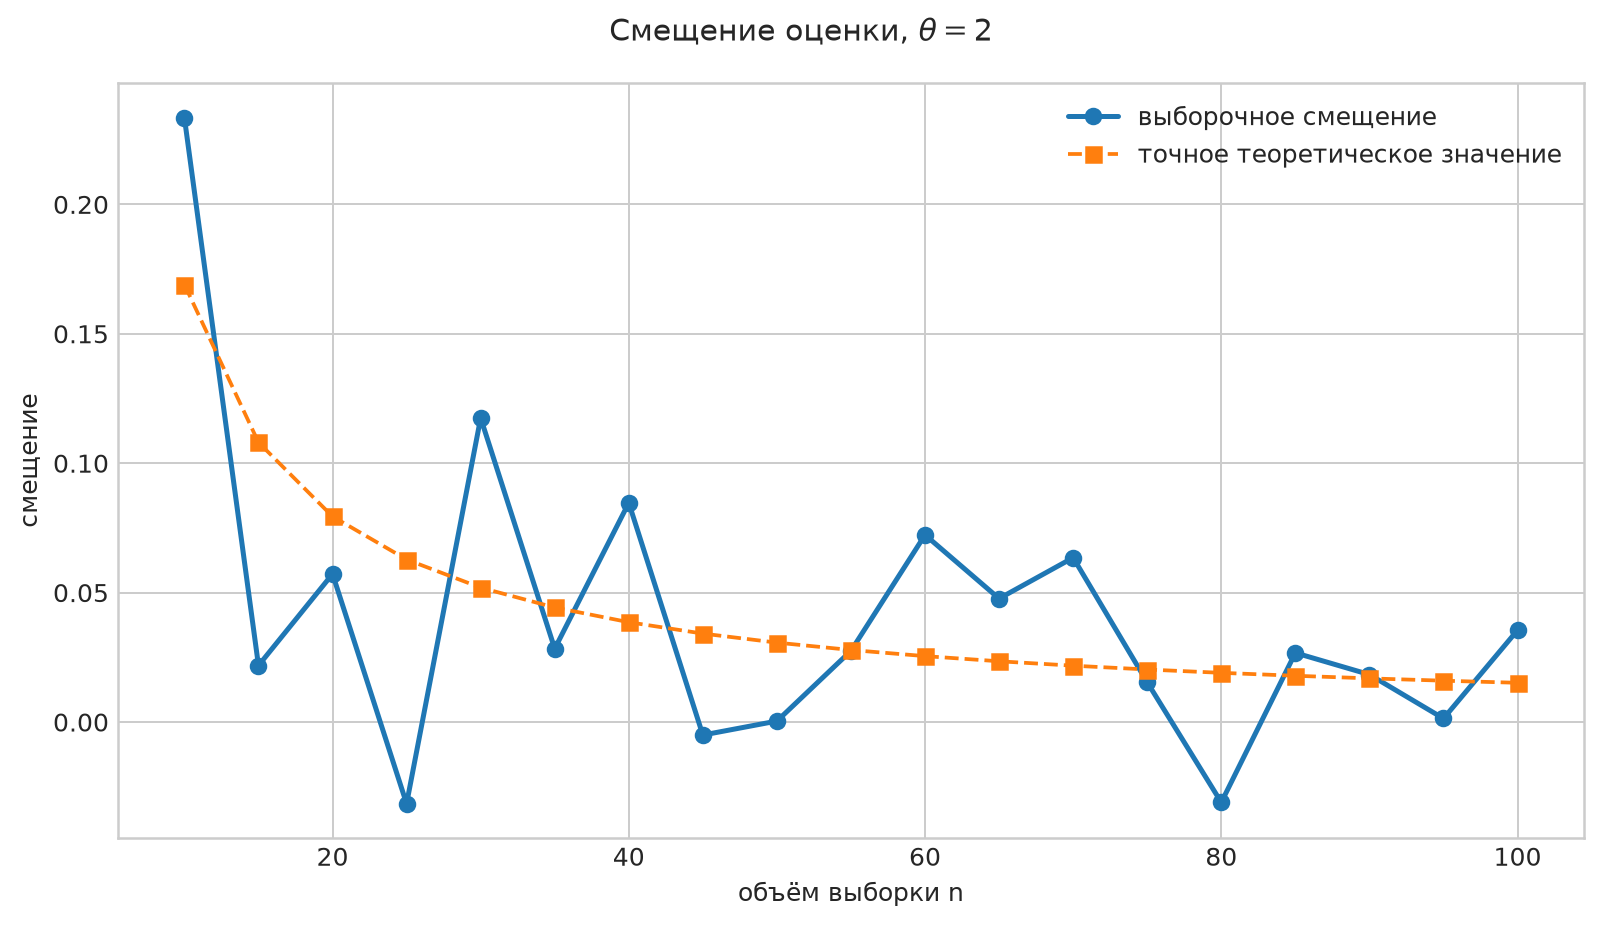

Отклонение выборочного смещения от точного теоретического:
n =     100: Δ = -0.010097
n =     650: Δ = +0.000650
n =    1200: Δ = -0.004829
n =    1750: Δ = -0.006157
n =    2300: Δ = -0.007791
n =    2850: Δ = -0.001203
n =    3400: Δ = -0.008847
n =    3950: Δ = -0.002100
n =    4500: Δ = -0.003739
n =    5050: Δ = +0.002382
n =    5600: Δ = -0.001030
n =    6150: Δ = +0.002181
n =    6700: Δ = -0.004136
n =    7250: Δ = -0.002993
n =    7800: Δ = +0.001994
n =    8350: Δ = -0.002514
n =    8900: Δ = -0.002495
n =    9450: Δ = +0.005647
n =   10000: Δ = -0.001615


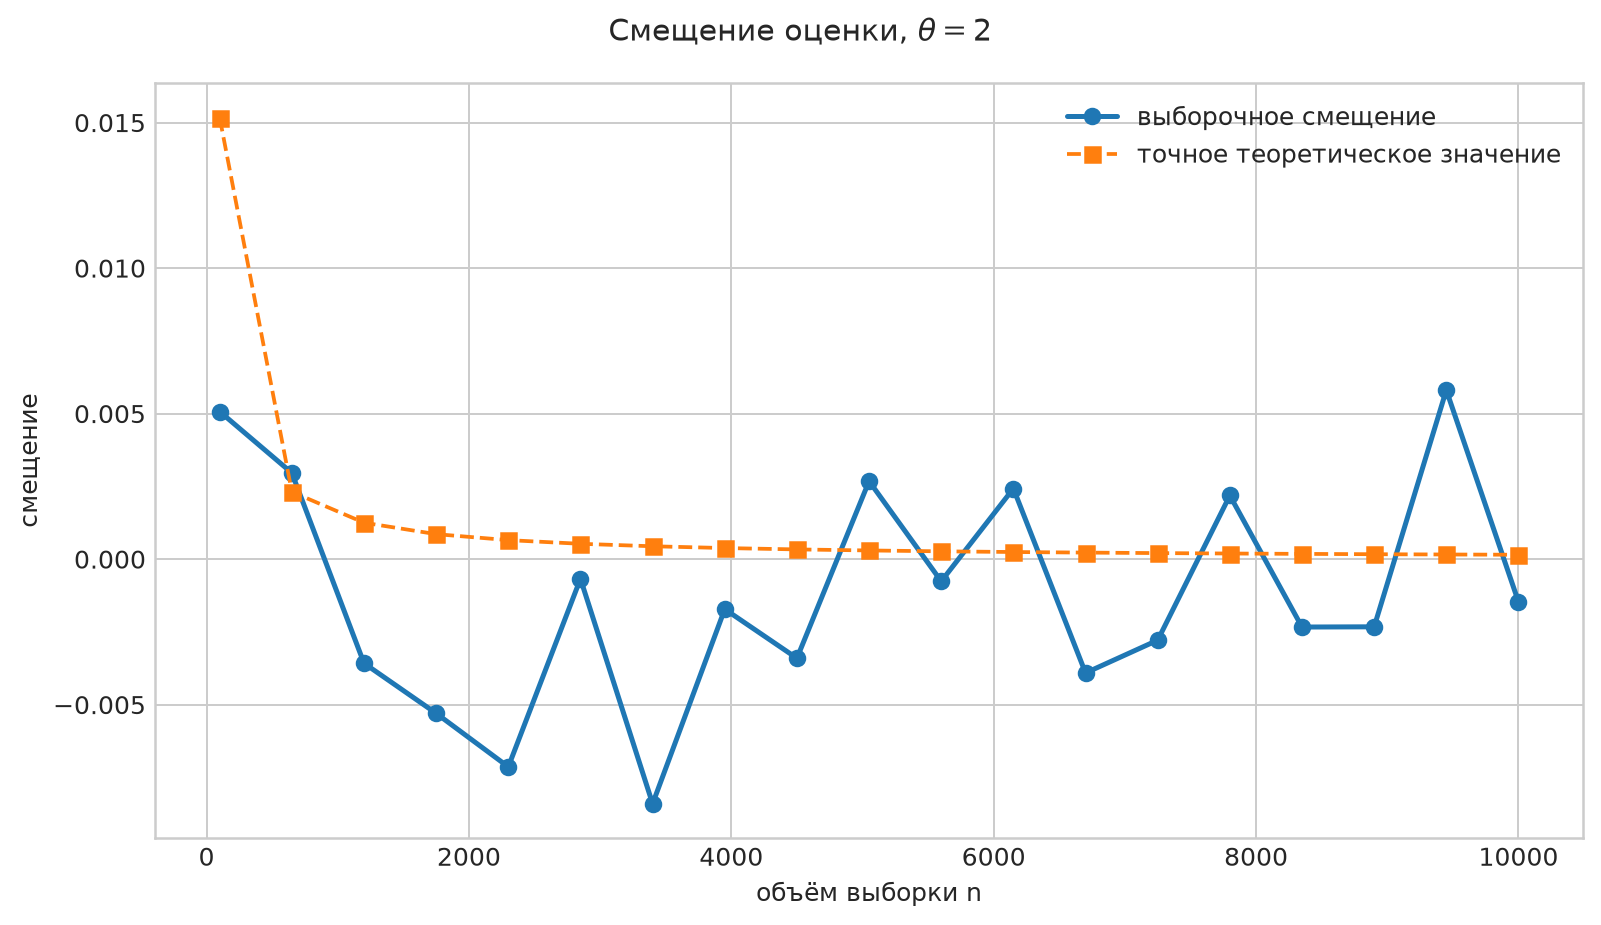

Отклонение выборочного смещения от точного теоретического:
n =  100000: Δ = -0.001335
n =  190000: Δ = -0.000938
n =  280000: Δ = +0.000548
n =  370000: Δ = -0.001023
n =  460000: Δ = -0.000064
n =  550000: Δ = +0.000486
n =  640000: Δ = -0.000063
n =  730000: Δ = -0.000311
n =  820000: Δ = +0.000819
n =  910000: Δ = +0.000198
n = 1000000: Δ = -0.000294


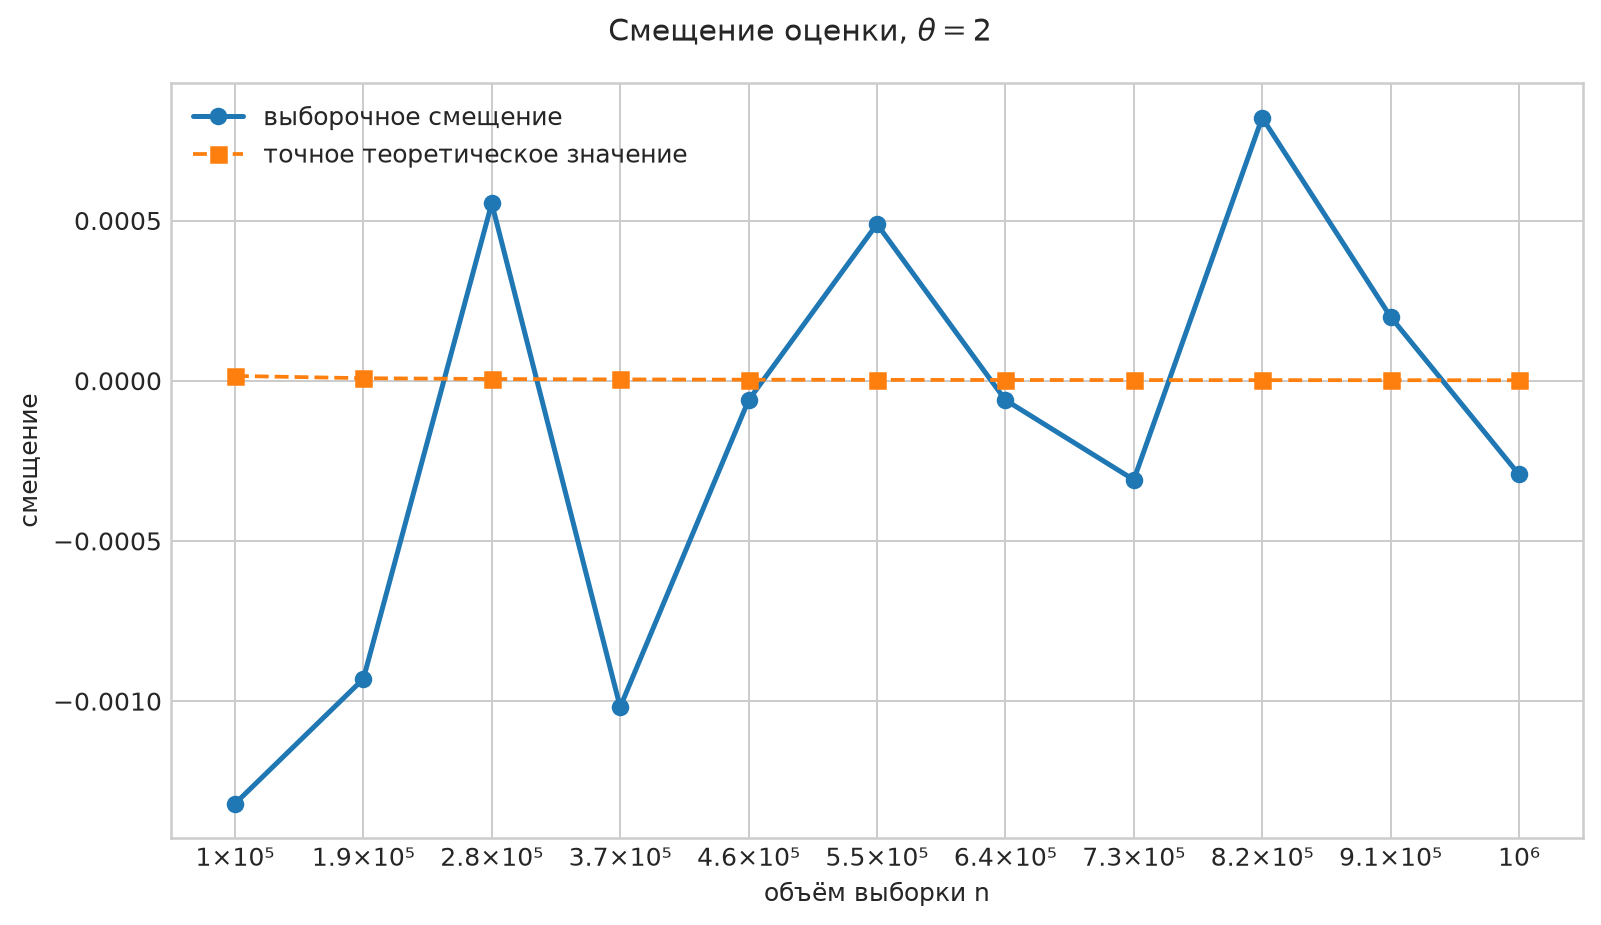

In [4]:
for sample_sizes, current_experiment in zip(N, experiments):
    print(
        "Отклонение выборочного смещения от точного теоретического:"
    )
    for n in sample_sizes:
        errors = current_experiment.estimates[int(n)] - THETA
        mean_bias = errors.mean()
        expected_bias = current_experiment.theoretical[int(n)].bias
        delta = mean_bias - expected_bias
        print(f"n = {n:7d}: Δ = {delta:+.6f}")

    bias_image = save_bias_comparison_plot(current_experiment)
    display(Image(filename=str(bias_image)))

### Вывод

Точное теоретическое смещение положительно и уменьшается с ростом $n$. Выборочное смещение колеблется около точной оранжевой линии, а расхождение стремится к нулю с ростом кол-ва итераций.

## Дисперсия оценки

### 1. Выборочная величина

Вычитание постоянного параметра $\theta$ не изменяет дисперсию. Поэтому выборочная дисперсия разностей $D_n^{(r)}=\widehat\theta_n^{(r)}-\theta$ совпадает с выборочной дисперсией $M$ полученных оценок:

$$\boxed{
\widehat{\operatorname{Var}}_n
=\frac1{M-1}\sum_{r=1}^{M}
\left(
\widehat\theta_n^{(r)}
-\overline{\widehat\theta}_n
\right)^2
}.$$

На верхней части графика фиолетовыми точками показаны сами отдельные оценки $\widehat\theta_n^{(r)}$. На нижней части синяя линия показывает вычисленную по ним выборочную дисперсию.

### 2. Точное теоретическое значение

Найдём дисперсию без асимптотического разложения. Введём

$$Y_i=1-X_i,
\qquad
T_n=\sum_{i=1}^{n}Y_i.$$

Поскольку $\overline X=1-T_n/n$, оценка представляется в виде

$$\widehat\theta_n
=\frac{\overline X}{1-\overline X}
=\frac{1-T_n/n}{T_n/n}
=\frac n{T_n}-1.$$

При $\theta=2$ величина $X_i$ имеет плотность $p_X(x)=2x$ на $(0,1)$. Поэтому $Y_i=1-X_i$ имеет плотность

$$p_Y(y)=2(1-y)\mathbb{1}(y\in(0,1)).$$

Её преобразование Лапласа вычисляется явно:

$$\psi_2(s)
=\mathbb E e^{-sY_i}
=2\int_0^1(1-y)e^{-sy}\,dy.$$

Используем

$$\int_0^1e^{-sy}\,dy=\frac{1-e^{-s}}s,$$

$$\int_0^1ye^{-sy}\,dy
=\frac{1-(1+s)e^{-s}}{s^2}.$$

Тогда

$$\boxed{
\psi_2(s)=\frac{2(s-1+e^{-s})}{s^2}
}.$$

Теперь найдём необходимые обратные моменты суммы $T_n$. Для $q>0$ справедливо точное тождество

$$z^{-q}=\frac1{\Gamma(q)}
\int_0^\infty s^{q-1}e^{-sz}\,ds.$$

Подставляем $z=T_n$ и берём математическое ожидание. Поскольку подынтегральная функция неотрицательна, по теореме Тонелли можно поменять местами ожидание и интеграл:

$$\mathbb E T_n^{-q}
=\frac1{\Gamma(q)}\int_0^\infty
s^{q-1}\mathbb E e^{-sT_n}\,ds.$$

Величины $Y_1,\ldots,Y_n$ независимы, поэтому

$$\mathbb E e^{-sT_n}
=\mathbb E e^{-s\sum_{i=1}^nY_i}
=\prod_{i=1}^n\mathbb E e^{-sY_i}
=\psi_2(s)^n.$$

Обозначим

$$I_q(n)=\mathbb E T_n^{-q}
=\frac1{\Gamma(q)}\int_0^\infty
s^{q-1}\psi_2(s)^n\,ds.$$

Нам нужны два случая:

$$I_1(n)=\int_0^\infty\psi_2(s)^n\,ds,$$

$$I_2(n)=\int_0^\infty s\psi_2(s)^n\,ds,$$

поскольку $\Gamma(1)=\Gamma(2)=1$. Эти интегралы конечны при $n>1$ и $n>2$ соответственно; во всех экспериментах $n\ge10$.

Из $\widehat\theta_n=n/T_n-1$ получаем первый момент оценки:

$$\mathbb E\widehat\theta_n
=n\mathbb E T_n^{-1}-1
=nI_1(n)-1.$$

Возведём оценку в квадрат:

$$\widehat\theta_n^2
=\left(\frac n{T_n}-1\right)^2
=\frac{n^2}{T_n^2}-\frac{2n}{T_n}+1.$$

Следовательно,

$$\mathbb E\widehat\theta_n^2
=n^2I_2(n)-2nI_1(n)+1.$$

По определению дисперсии

$$\operatorname{Var}(\widehat\theta_n)
=\mathbb E\widehat\theta_n^2
-\left(\mathbb E\widehat\theta_n\right)^2.$$

Подставляем найденные моменты:

$$\operatorname{Var}(\widehat\theta_n)
=n^2I_2-2nI_1+1
-\left(nI_1-1\right)^2.$$

Раскрываем квадрат и сокращаем одинаковые слагаемые:

$$\boxed{
\operatorname{Var}(\widehat\theta_n)
=n^2\left(I_2(n)-I_1(n)^2\right)
}.$$

Это точная формула, а не асимптотика. При $\theta=2$ она имеет явный интегральный вид

$$\boxed{
\operatorname{Var}(\widehat\theta_n)
=n^2\left[
\int_0^\infty s
\left(\frac{2(s-1+e^{-s})}{s^2}\right)^n\,ds
-\left(
\int_0^\infty
\left(\frac{2(s-1+e^{-s})}{s^2}\right)^n\,ds
\right)^2
\right]
}.$$

Для устойчивого вычисления при больших $n$ в коде используется замена $s=u/n$. Введём

$$A_1(n)=nI_1(n)
=\int_0^\infty \psi_2\left(\frac un\right)^n\,du,$$

$$A_2(n)=n^2I_2(n)
=\int_0^\infty u\psi_2\left(\frac un\right)^n\,du.$$

Тогда та же точная дисперсия записывается компактно:

$$\boxed{
\operatorname{Var}(\widehat\theta_n)=A_2(n)-A_1(n)^2
}.$$

Численное интегрирование этой формулы даёт, например,

$$\operatorname{Var}(\widehat\theta_{10})\approx0.64706582,$$

$$\operatorname{Var}(\widehat\theta_{100})\approx0.04648044,$$

$$\operatorname{Var}(\widehat\theta_{10^6})\approx4.50007\cdot10^{-6}.$$

Именно эти точные теоретические значения с погрешностью численного интегрирования образуют оранжевую линию. Синяя линия — выборочная дисперсия разностей $D_n^{(r)}=\widehat\theta_n^{(r)}-\theta$; она совпадает с выборочной дисперсией самих оценок, поскольку вычитание постоянной $\theta$ не меняет дисперсию.

Отклонение выборочной дисперсии от точной теоретической:
n =      10: Δ = +0.628117
n =      15: Δ = -0.067213
n =      20: Δ = -0.057601
n =      25: Δ = -0.027100
n =      30: Δ = -0.004020
n =      35: Δ = +0.023801
n =      40: Δ = -0.020651
n =      45: Δ = -0.019210
n =      50: Δ = +0.008797
n =      55: Δ = +0.029182
n =      60: Δ = +0.005023
n =      65: Δ = +0.001576
n =      70: Δ = +0.040235
n =      75: Δ = -0.009066
n =      80: Δ = -0.006559
n =      85: Δ = +0.007314
n =      90: Δ = -0.003211
n =      95: Δ = -0.006736
n =     100: Δ = +0.003181


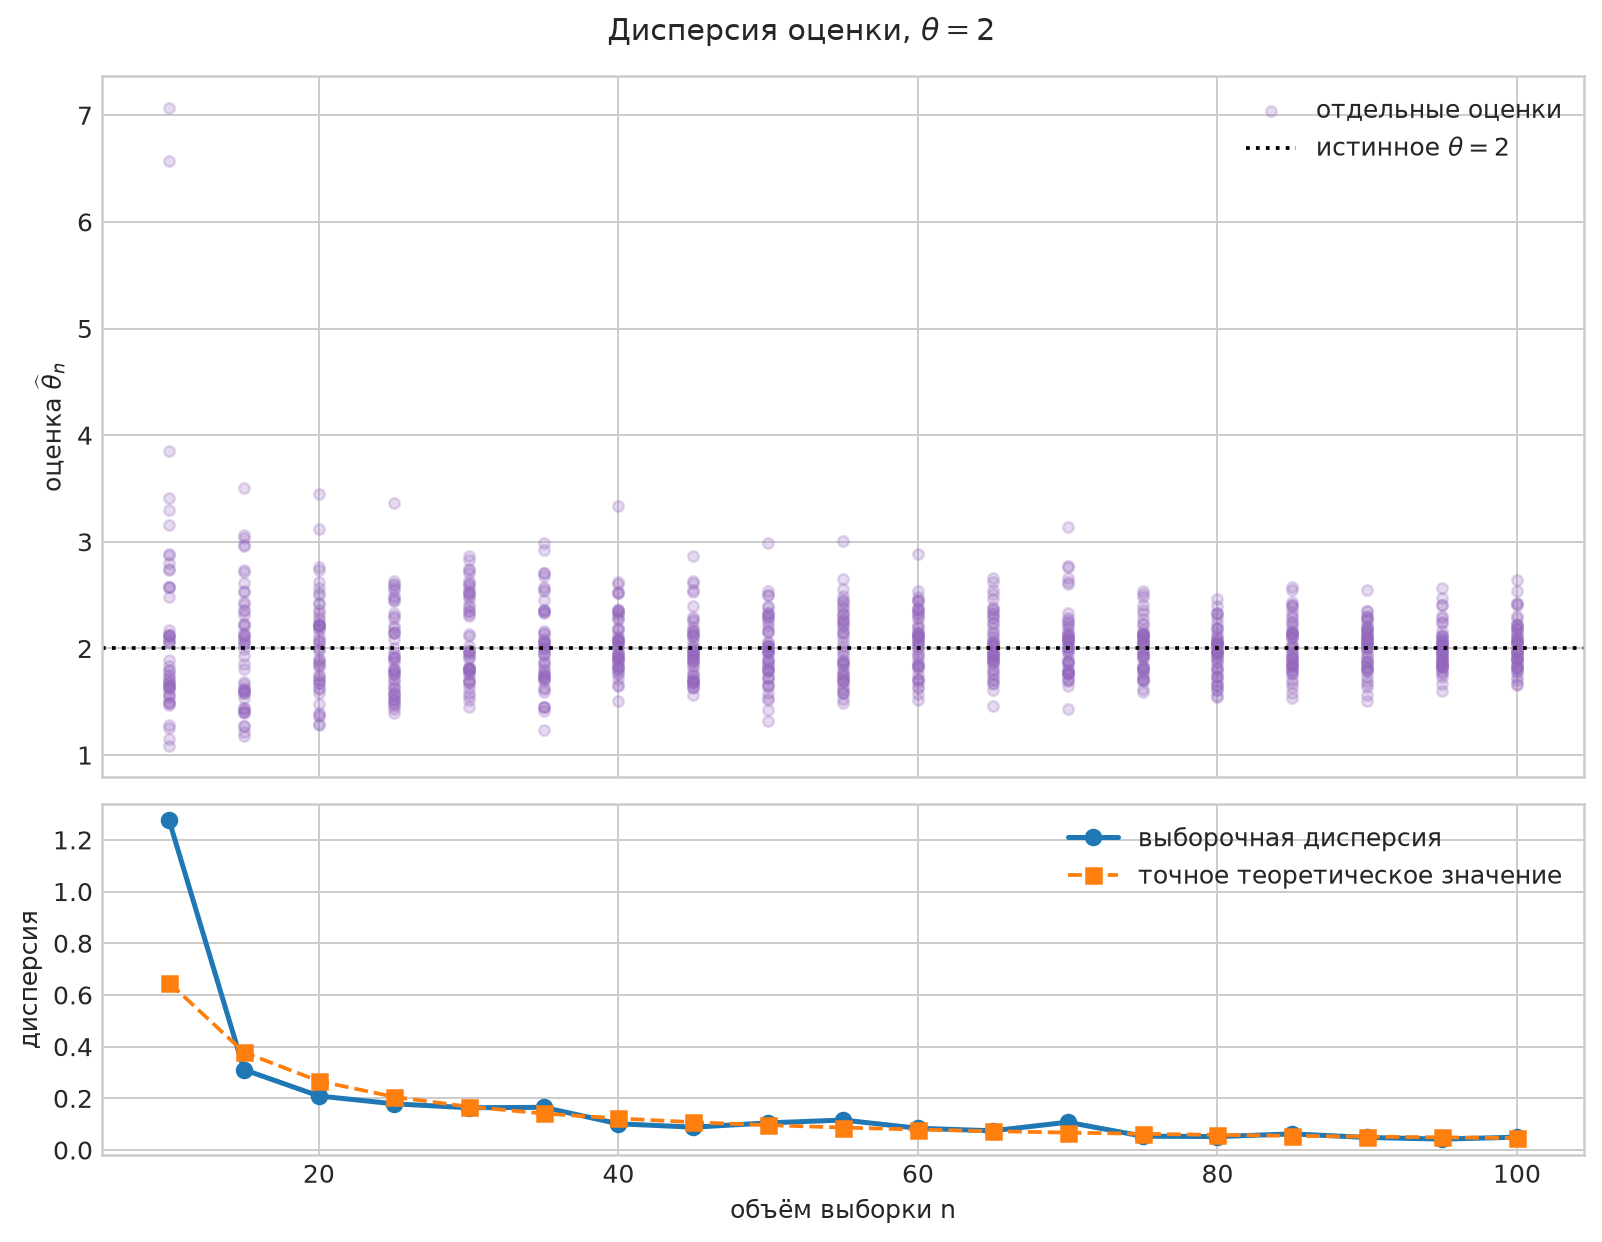

Отклонение выборочной дисперсии от точной теоретической:
n =     100: Δ = +0.014736
n =     650: Δ = -0.001097
n =    1200: Δ = +0.000933
n =    1750: Δ = -0.000266
n =    2300: Δ = +0.000266
n =    2850: Δ = -0.000147
n =    3400: Δ = -0.000195
n =    3950: Δ = -0.000236
n =    4500: Δ = +0.000126
n =    5050: Δ = -0.000209
n =    5600: Δ = +0.000160
n =    6150: Δ = -0.000165
n =    6700: Δ = +0.000013
n =    7250: Δ = -0.000299
n =    7800: Δ = -0.000176
n =    8350: Δ = +0.000065
n =    8900: Δ = -0.000140
n =    9450: Δ = -0.000062
n =   10000: Δ = +0.000048


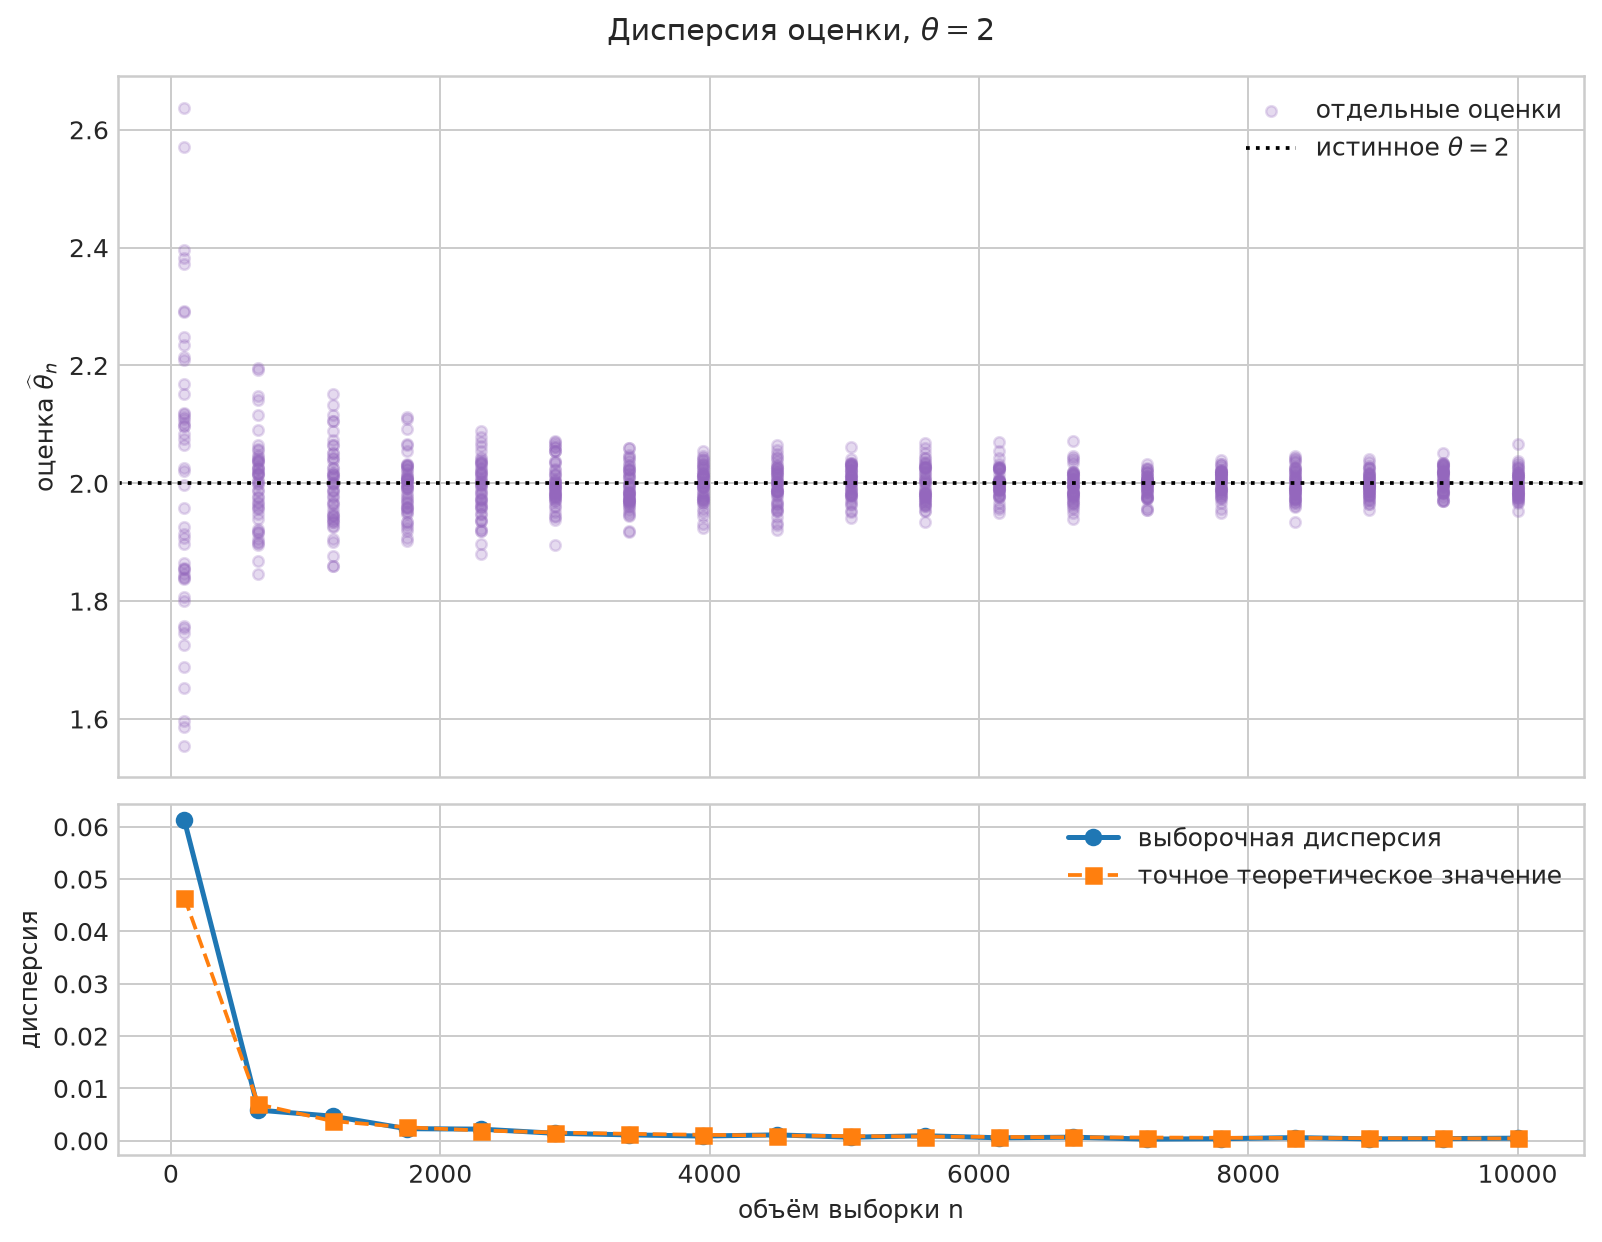

Отклонение выборочной дисперсии от точной теоретической:
n =  100000: Δ = -0.000010
n =  190000: Δ = -0.000002
n =  280000: Δ = +0.000005
n =  370000: Δ = +0.000002
n =  460000: Δ = +0.000001
n =  550000: Δ = -0.000002
n =  640000: Δ = -0.000002
n =  730000: Δ = -0.000001
n =  820000: Δ = -0.000002
n =  910000: Δ = +0.000000
n = 1000000: Δ = +0.000001


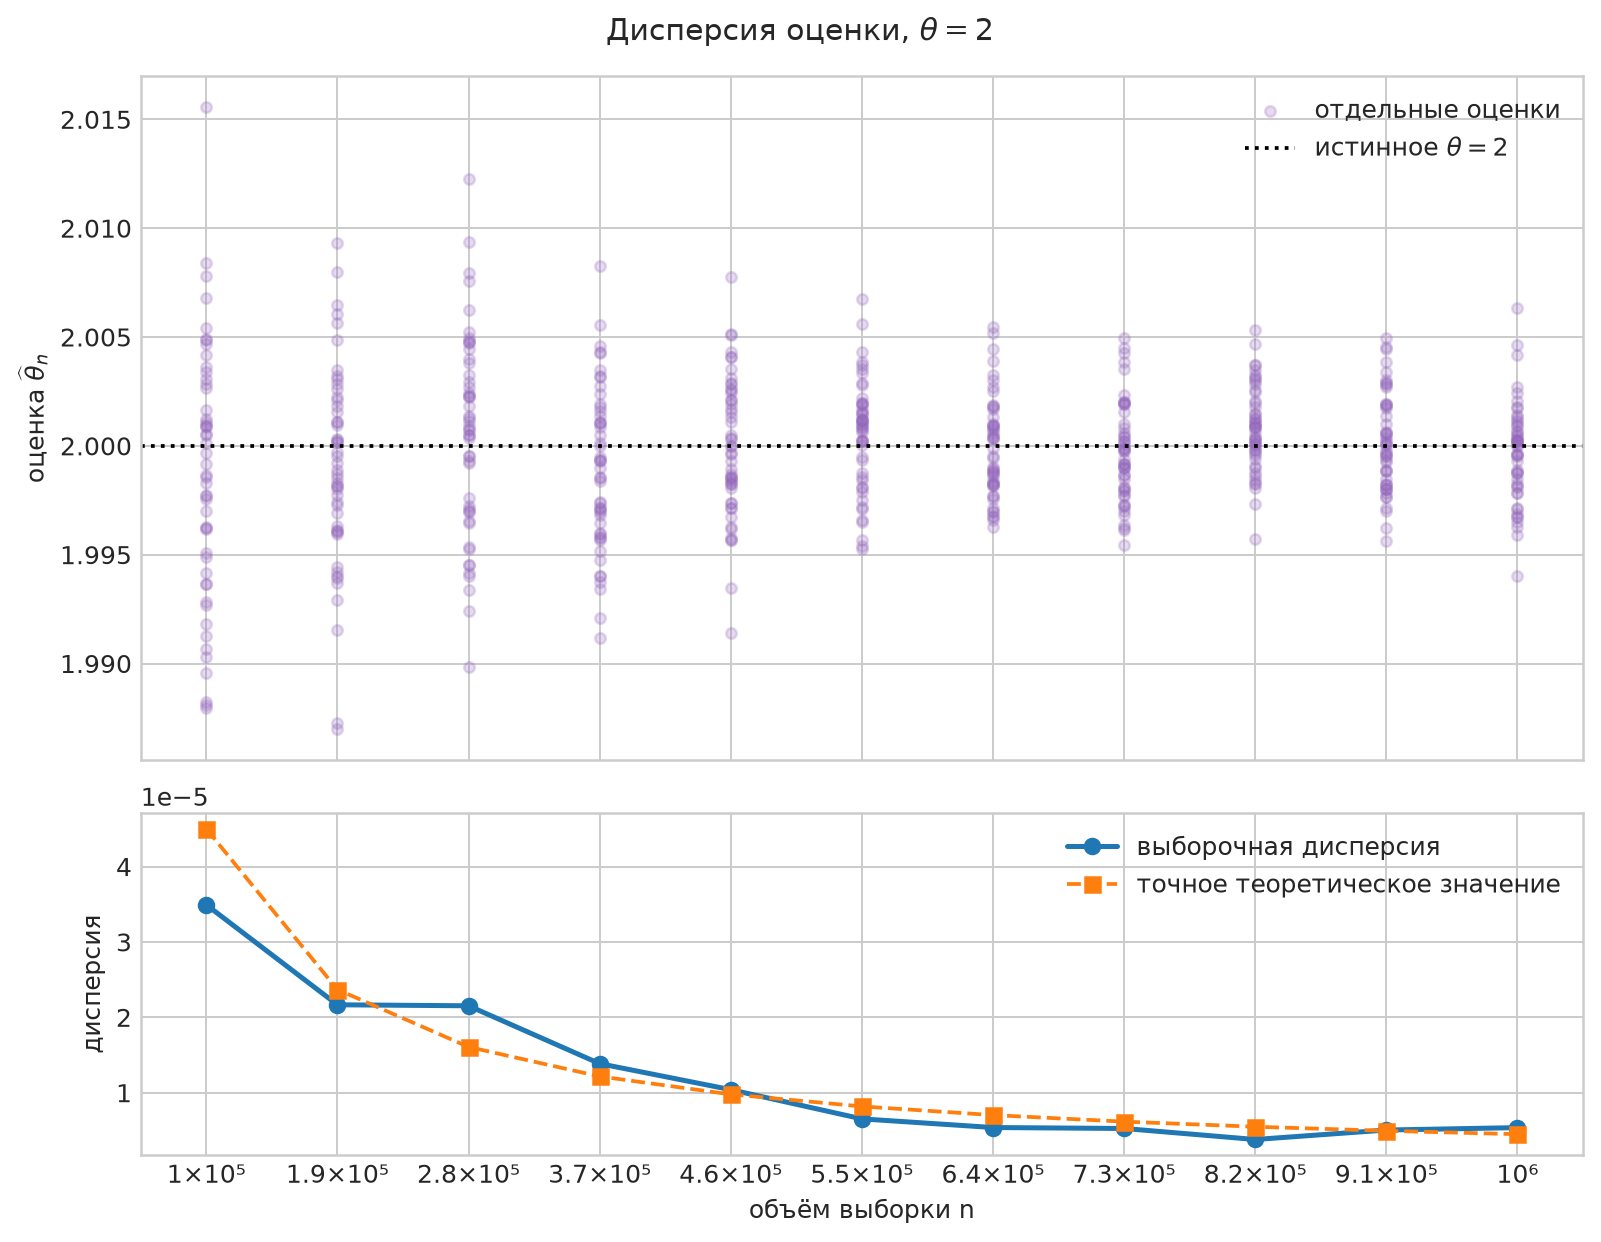

In [5]:
for sample_sizes, current_experiment in zip(N, experiments):
    print(
        "Отклонение выборочной дисперсии от точной теоретической:"
    )
    for n in sample_sizes:
        estimates = current_experiment.estimates[int(n)]
        mean_variance = estimates.var(ddof=1)
        expected_variance = current_experiment.theoretical[int(n)].variance
        delta = mean_variance - expected_variance
        print(f"n = {n:7d}: Δ = {delta:+.6f}")

    variance_image = save_variance_comparison_plot(current_experiment)
    display(Image(filename=str(variance_image)))

### Мини-вывод

Точная дисперсия убывает при увеличении $n$, поэтому отдельные оценки всё плотнее концентрируются около $\theta=2$. Выборочная дисперсия воспроизводит это поведение на всех трёх шкалах.

## Среднеквадратическая ошибка

### 1. Выборочная величина

Для каждой оценки квадрат отклонения от истинного параметра равен

$$Q_n^{(r)}=
\left(\widehat\theta_n^{(r)}-\theta\right)^2.$$

Выборочная MSE — среднее этих значений:

$$\boxed{
\widehat{\operatorname{MSE}}_n
=\frac1M\sum_{r=1}^{M}Q_n^{(r)}
}.$$

На графике синяя линия показывает выборочную MSE, то есть среднее квадратов отклонений от $\theta$, а оранжевая — точную теоретическую MSE.

### 2. Точное теоретическое значение

Используем точное тождество

$$\operatorname{MSE}_\theta(\widehat\theta_n)
=\operatorname{Var}_\theta(\widehat\theta_n)
+\operatorname{Bias}_\theta(\widehat\theta_n)^2.$$

Подставляем найденные через $A_1$ и $A_2$ значения:

$$\boxed{
\operatorname{MSE}_\theta(\widehat\theta_n)
=A_2-A_1^2+
\left(A_1-1-\theta\right)^2
}.$$

После раскрытия скобок получаем эквивалентную формулу

$$\boxed{
\operatorname{MSE}_\theta(\widehat\theta_n)
=A_2-2(\theta+1)A_1+(\theta+1)^2
}.$$

Таким образом, MSE также вычисляется точно через те же два одномерных интеграла. Перед графиком выводится разность выборочной и точной теоретической MSE.

Для результатов эксперимента дополнительно выполняется проверочное равенство

$$\widehat{\operatorname{MSE}}_n
=\frac{M-1}{M}\widehat{\operatorname{Var}}_n
+\widehat{\operatorname{Bias}}_n^2.$$


Отклонение выборочной MSE от точной теоретической:
n =      10: Δ = +0.628553
n =      15: Δ = -0.084628
n =      20: Δ = -0.064818
n =      25: Δ = -0.033621
n =      30: Δ = +0.003812
n =      35: Δ = +0.019343
n =      40: Δ = -0.016997
n =      45: Δ = -0.022120
n =      50: Δ = +0.005758
n =      55: Δ = +0.026844
n =      60: Δ = +0.007916
n =      65: Δ = +0.001813
n =      70: Δ = +0.041642
n =      75: Δ = -0.010314
n =      80: Δ = -0.006997
n =      85: Δ = +0.006462
n =      90: Δ = -0.004132
n =      95: Δ = -0.007834
n =     100: Δ = +0.003217


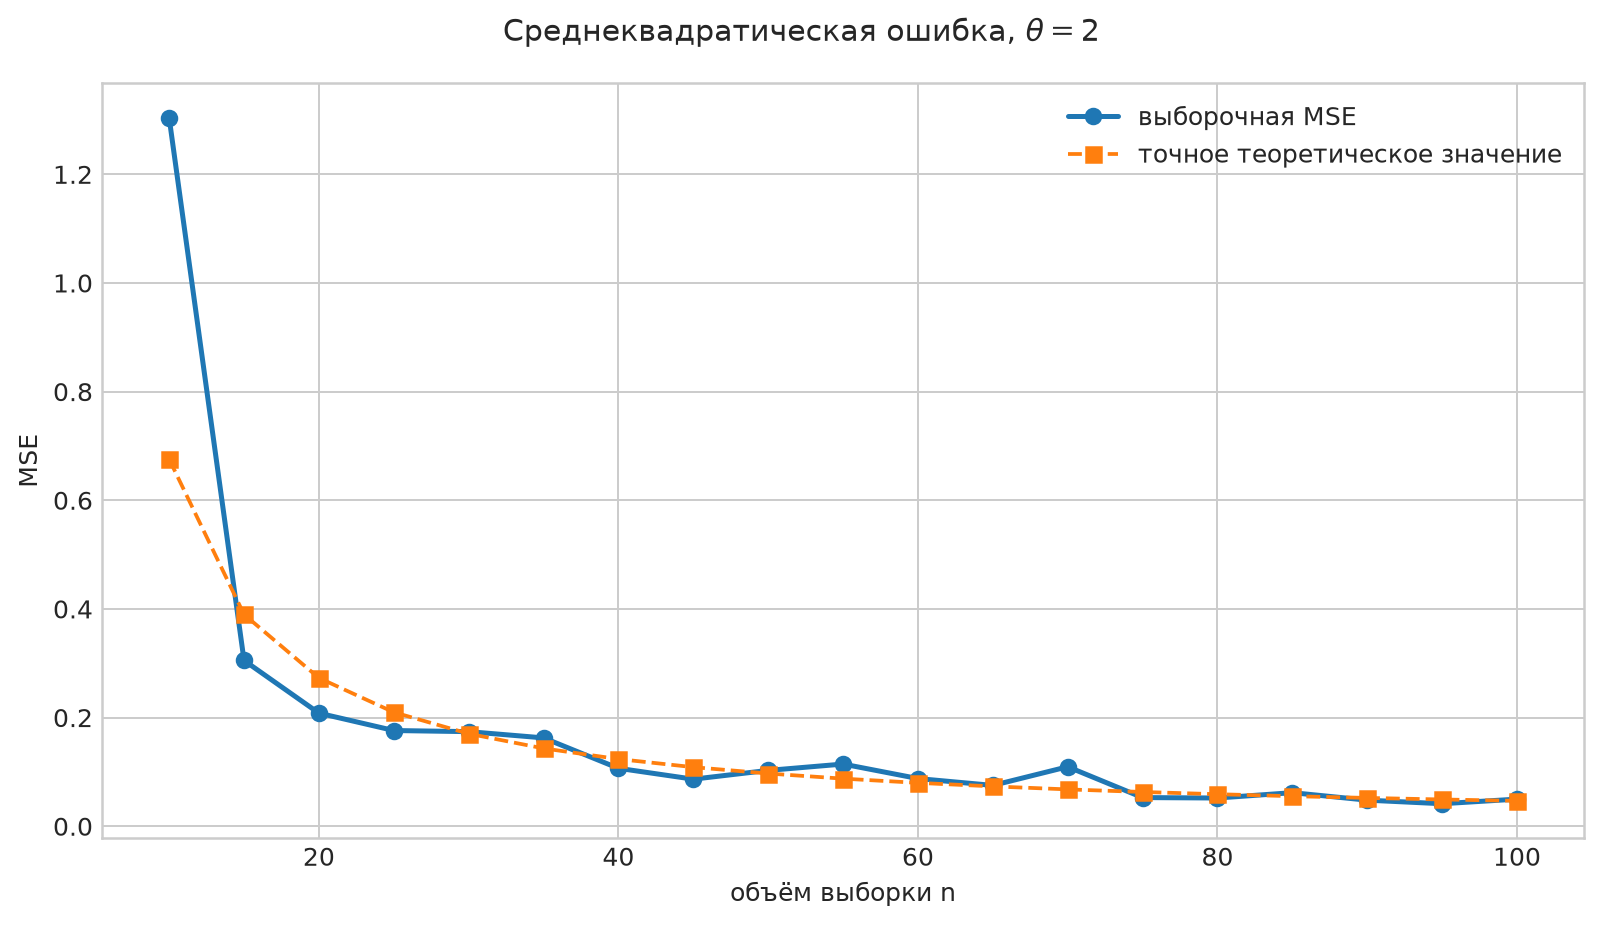

Отклонение выборочной MSE от точной теоретической:
n =     100: Δ = +0.013307
n =     650: Δ = -0.001211
n =    1200: Δ = +0.000850
n =    1750: Δ = -0.000285
n =    2300: Δ = +0.000272
n =    2850: Δ = -0.000175
n =    3400: Δ = -0.000147
n =    3950: Δ = -0.000251
n =    4500: Δ = +0.000115
n =    5050: Δ = -0.000215
n =    5600: Δ = +0.000141
n =    6150: Δ = -0.000170
n =    6700: Δ = +0.000014
n =    7250: Δ = -0.000298
n =    7800: Δ = -0.000179
n =    8350: Δ = +0.000058
n =    8900: Δ = -0.000142
n =    9450: Δ = -0.000037
n =   10000: Δ = +0.000040


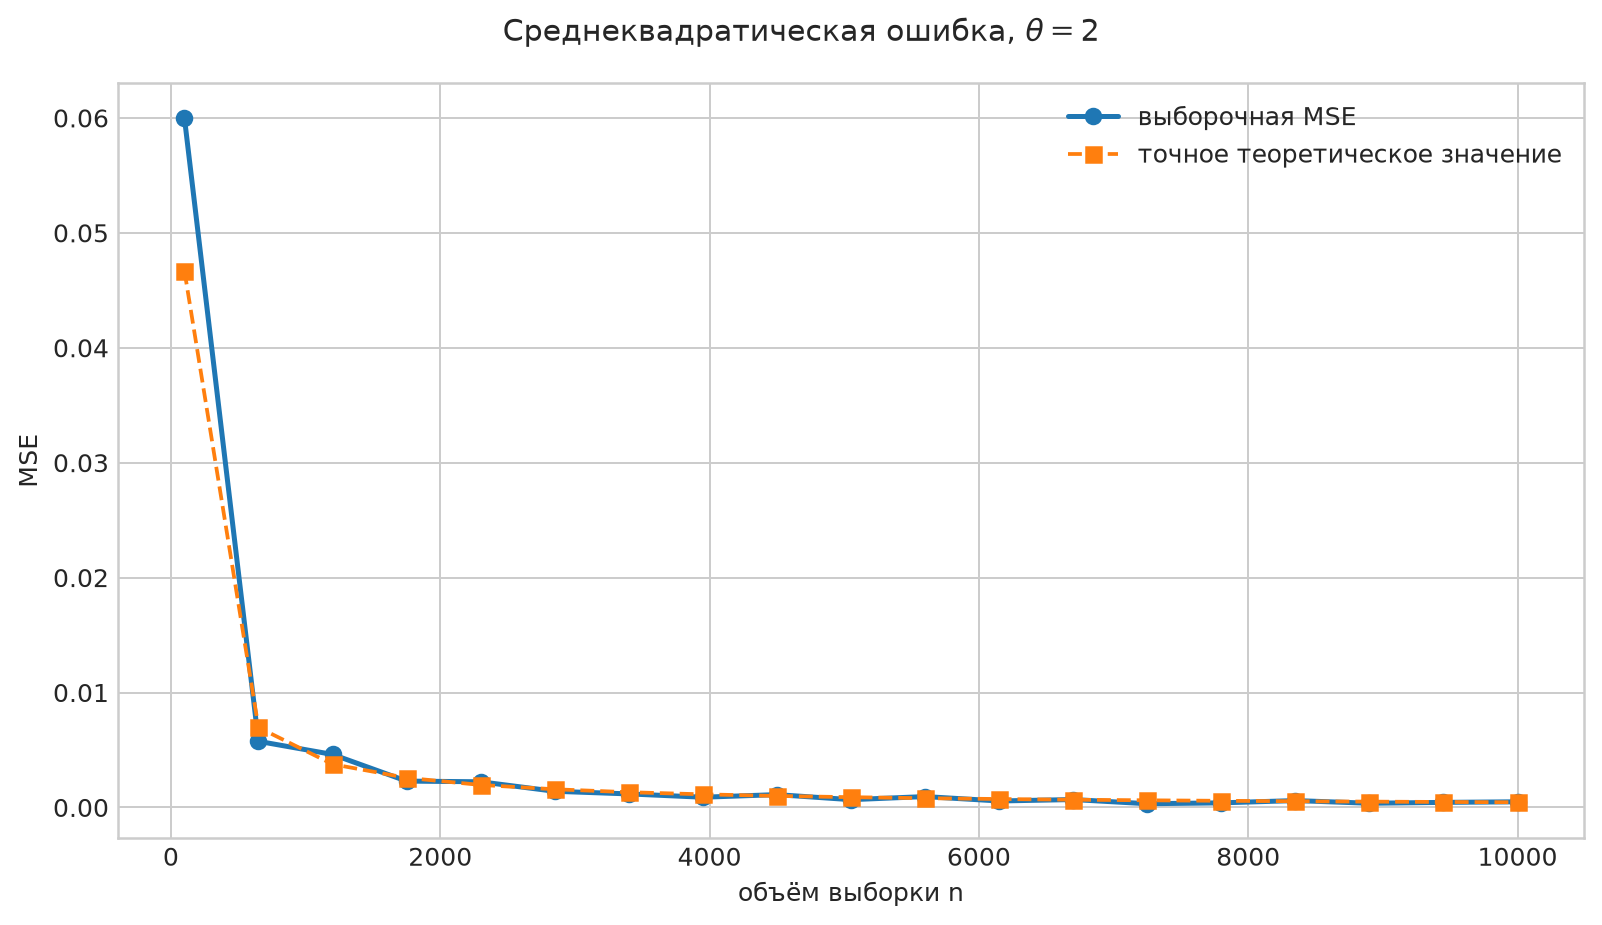

Отклонение выборочной MSE от точной теоретической:
n =  100000: Δ = -0.000009
n =  190000: Δ = -0.000002
n =  280000: Δ = +0.000005
n =  370000: Δ = +0.000002
n =  460000: Δ = +0.000000
n =  550000: Δ = -0.000002
n =  640000: Δ = -0.000002
n =  730000: Δ = -0.000001
n =  820000: Δ = -0.000001
n =  910000: Δ = +0.000000
n = 1000000: Δ = +0.000001


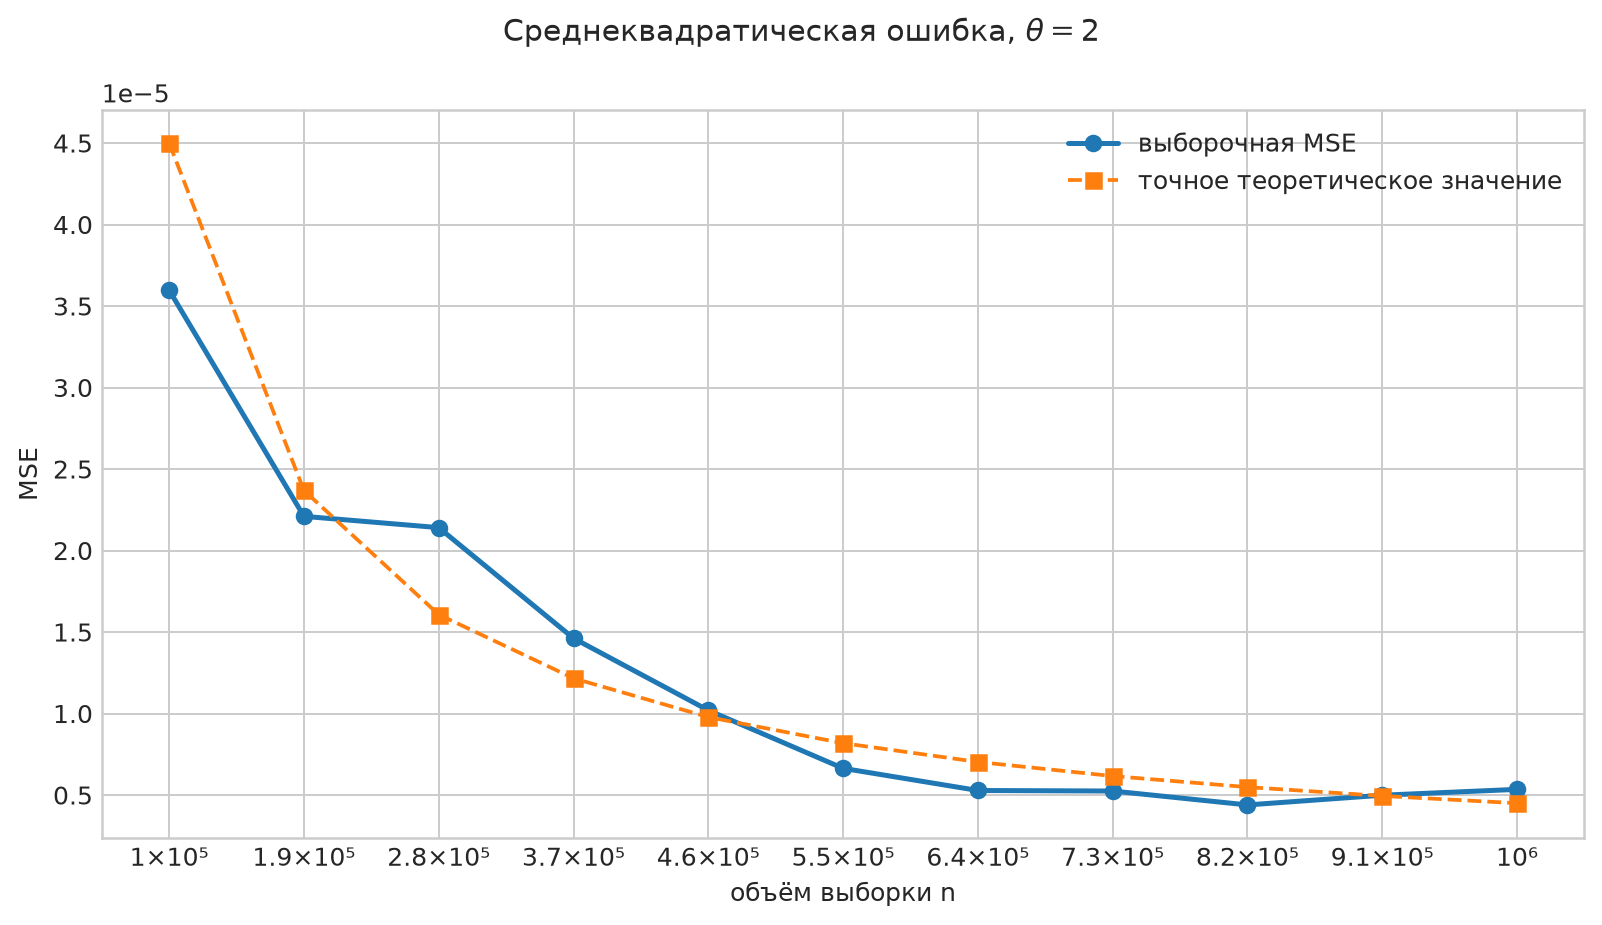

In [6]:
for sample_sizes, current_experiment in zip(N, experiments):
    print(
        "Отклонение выборочной MSE от точной теоретической:"
    )
    for n in sample_sizes:
        errors = current_experiment.estimates[int(n)] - THETA
        mean_mse = np.mean(errors**2)
        expected_mse = current_experiment.theoretical[int(n)].mse
        delta = mean_mse - expected_mse
        print(f"n = {n:7d}: Δ = {delta:+.6f}")

    mse_image = save_mse_comparison_plot(current_experiment)
    display(Image(filename=str(mse_image)))

### Мини-вывод

Точная MSE стремится к нулю. Это означает, что одновременно уменьшаются разброс оценок и их систематическое отклонение от истинного параметра.

## Свойства оценки

### Смещённость

Функция $g(x)=x/(1-x)$ строго выпукла на $(0,1)$. Для $n>1$ по строгому неравенству Йенсена

$$\mathbb E_\theta\widehat\theta_n
=\mathbb E_\theta g(\overline X)
>g(\mathbb E_\theta\overline X)
=g\!\left(\frac\theta{\theta+1}\right)=\theta.$$

Следовательно, оценка положительно смещена.

### Состоятельность

По усиленному закону больших чисел

$$\overline X\xrightarrow{a.s.}\frac\theta{\theta+1}.$$

Функция $g$ непрерывна в этой точке, поэтому

$$\widehat\theta_n=g(\overline X)
\xrightarrow{a.s.}g\!\left(\frac\theta{\theta+1}\right)=\theta.$$

Значит, оценка сильно состоятельна.

### Асимптотическая нормальность

Для $X\sim\operatorname{Beta}(\theta,1)$

$$\operatorname{Var}_\theta(X)
=\frac{\theta}{(\theta+1)^2(\theta+2)},
\qquad
g'\!\left(\frac\theta{\theta+1}\right)=(\theta+1)^2.$$

Из центральной предельной теоремы и дельта-метода следует

$$\boxed{\sqrt n(\widehat\theta_n-\theta)
\Rightarrow N\!\left(0,
\frac{\theta(\theta+1)^2}{\theta+2}\right)}.$$

### Асимптотическая эффективность

Информация Фишера в одном наблюдении равна $I(\theta)=1/\theta^2$, поэтому граница Крамера—Рао для асимптотической дисперсии имеет коэффициент $\theta^2$. Для оценки метода моментов коэффициент равен $\theta(\theta+1)^2/(\theta+2)$, а их отношение

$$\frac{(\theta+1)^2}{\theta(\theta+2)}
=1+\frac1{\theta(\theta+2)}>1.$$

Следовательно, оценка не является асимптотически эффективной.

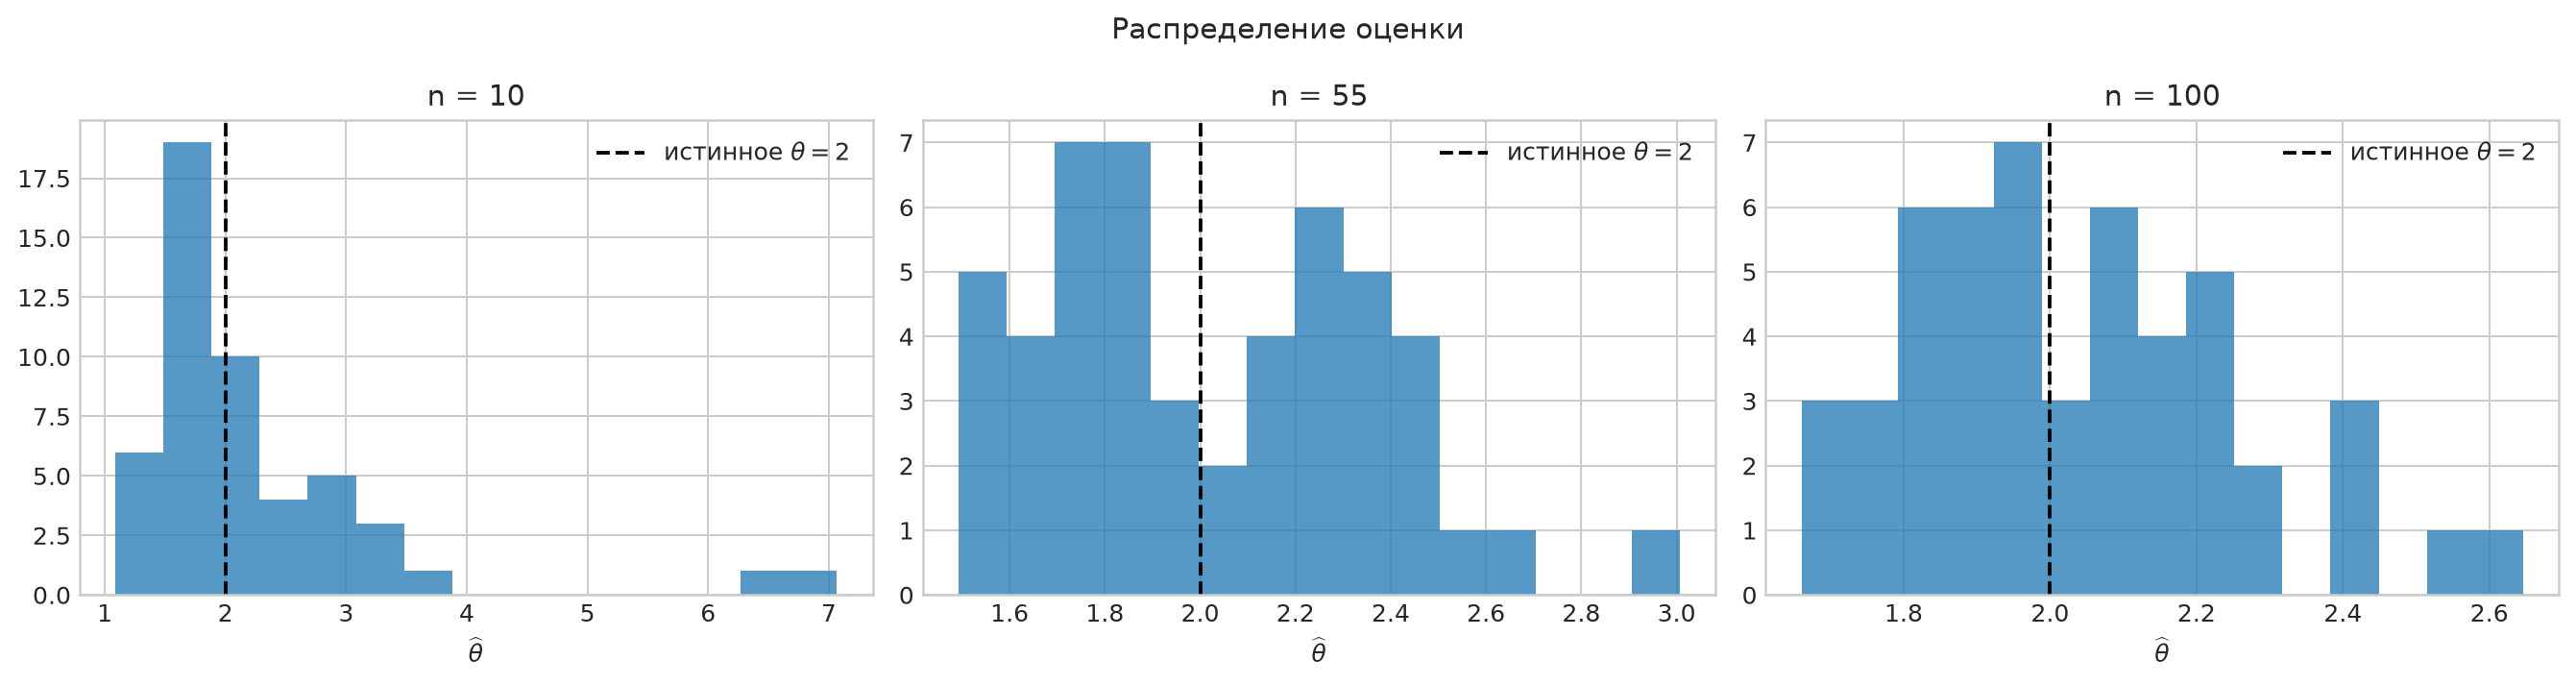

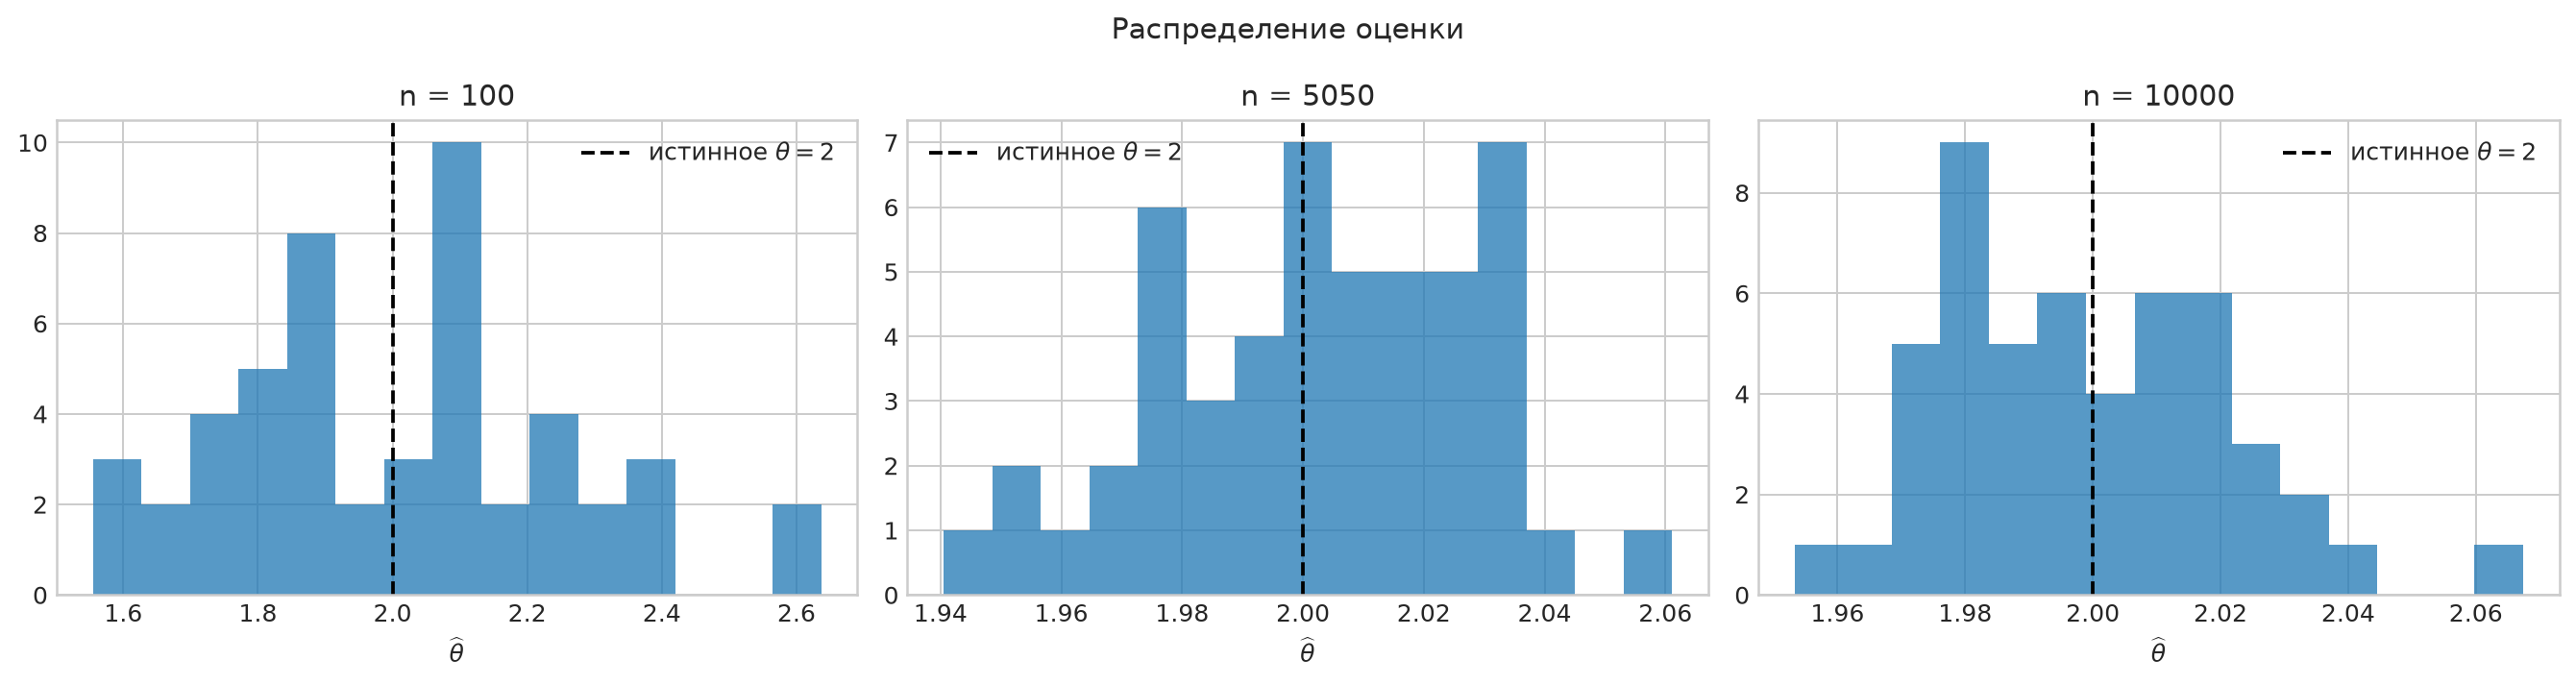

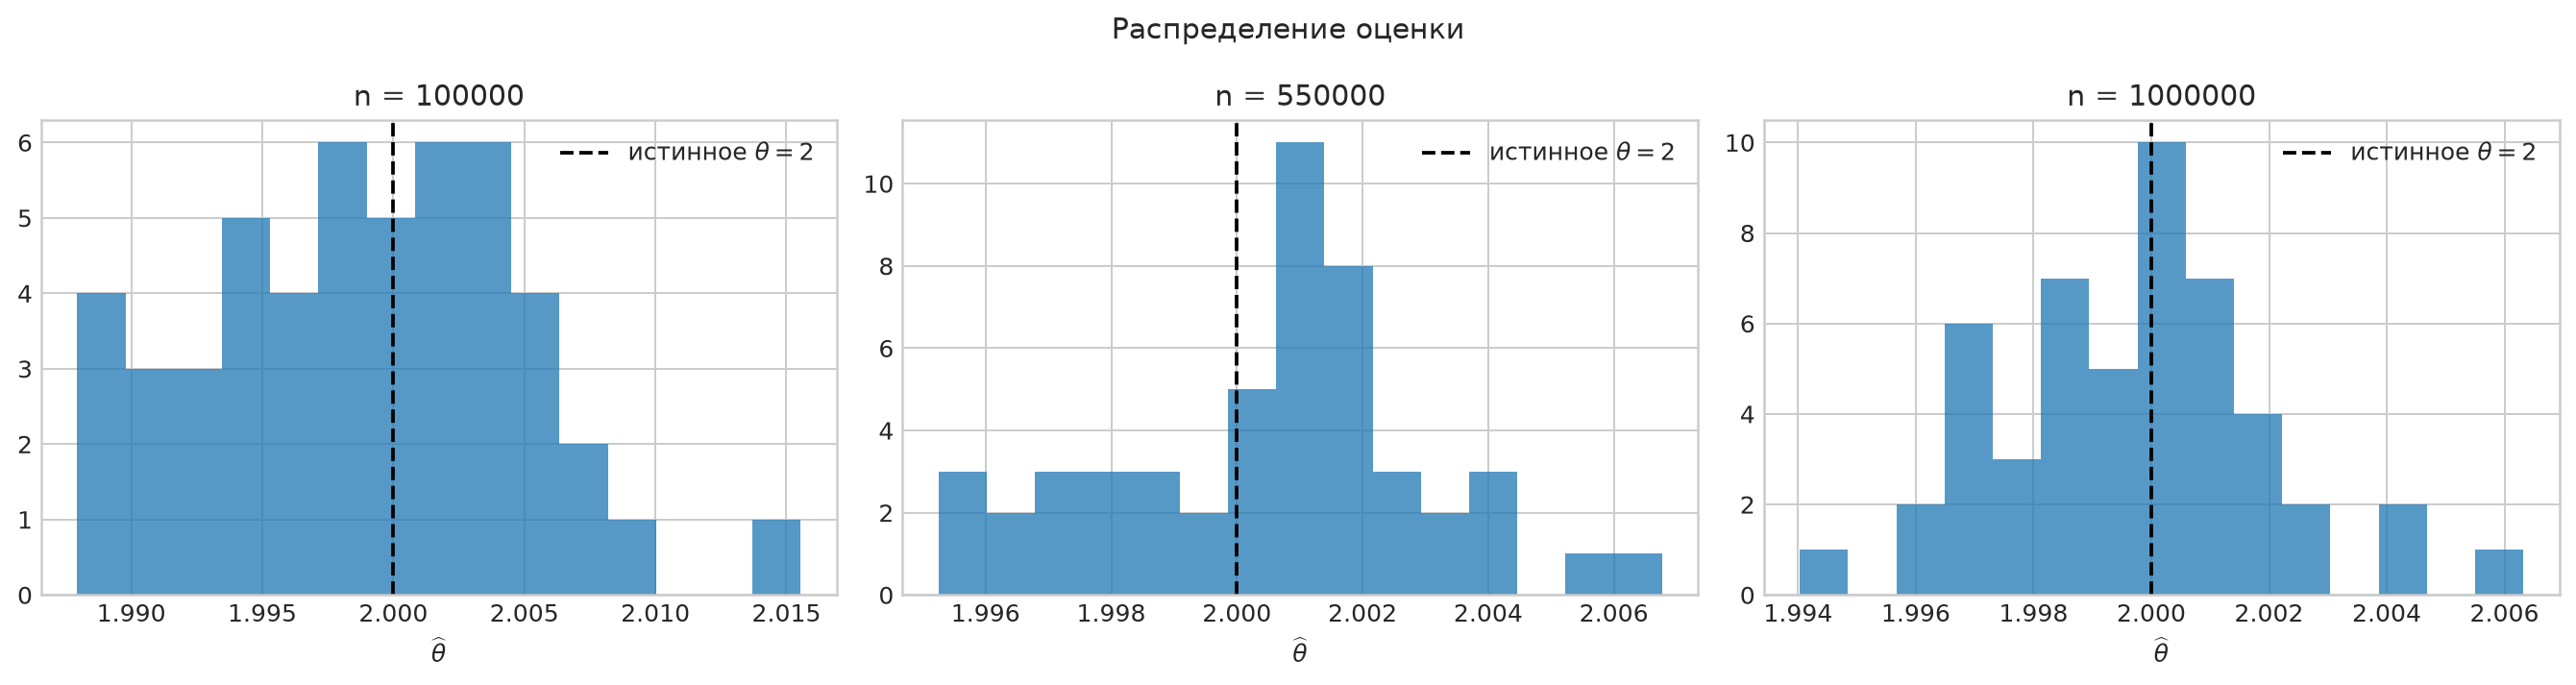

In [7]:
for current_experiment in experiments:
    distribution_image = save_estimate_distributions_plot(
        current_experiment
    )
    display(Image(filename=str(distribution_image)))

### Мини-вывод

При росте $n$ распределение $\widehat\theta_n$ сужается и концентрируется около $\theta=2$, что согласуется с состоятельностью и асимптотической нормальностью оценки.

## Превышение заданного порога

Относительный порог задаётся константой `ERROR_THRESHOLD = 0.1`. При $\theta=2$ соответствующий абсолютный порог равен

$$\varepsilon=\theta\cdot0.1=2\cdot0.1=0.2.$$

Для каждой из $M=50$ повторных выборок определим индикатор выхода оценки за допустимые границы:

$$I_n^{(r)}=
\mathbf{1}\bigl(\left|\widehat{\theta}_n^{(r)}-\theta\right|>\varepsilon\bigr).$$

Число вышедших за границы оценок равно

$$\boxed{
K_n=\sum_{r=1}^{M}I_n^{(r)}
}.$$

Соответствующая выборочная доля превышений равна

$$\widehat{p}_n=\frac{K_n}{M}.$$

Допустимый интервал имеет вид

$$\boxed{
[\theta-\varepsilon,\theta+\varepsilon]=[1.8,2.2]
}.$$

Пороговая визуализация строится отдельно для всех трёх шкал `N`. На верхней части каждого графика фиолетовыми точками показаны отдельные оценки, зелёной полосой — допустимый интервал $[1.8,2.2]$. На нижней части показано число превышений $K_n$ из $M=50$; возле каждой точки подписано его точное значение.

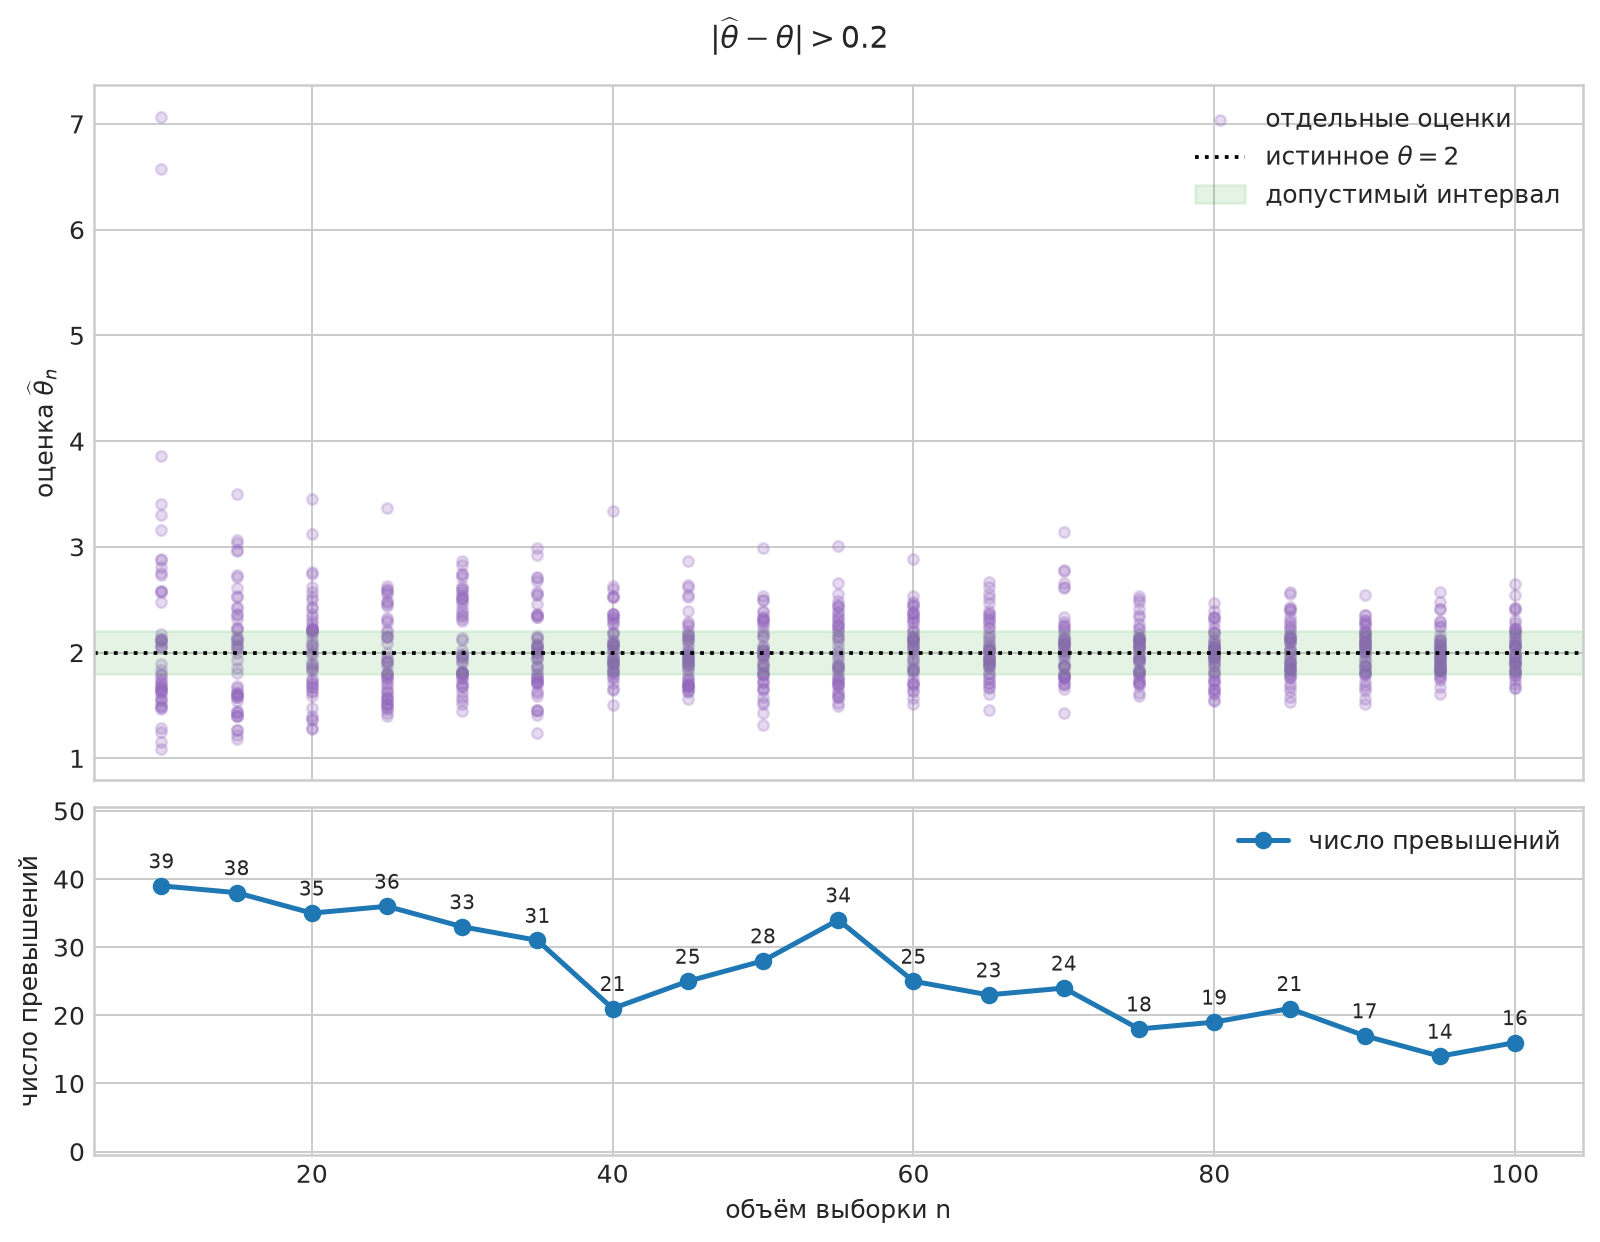

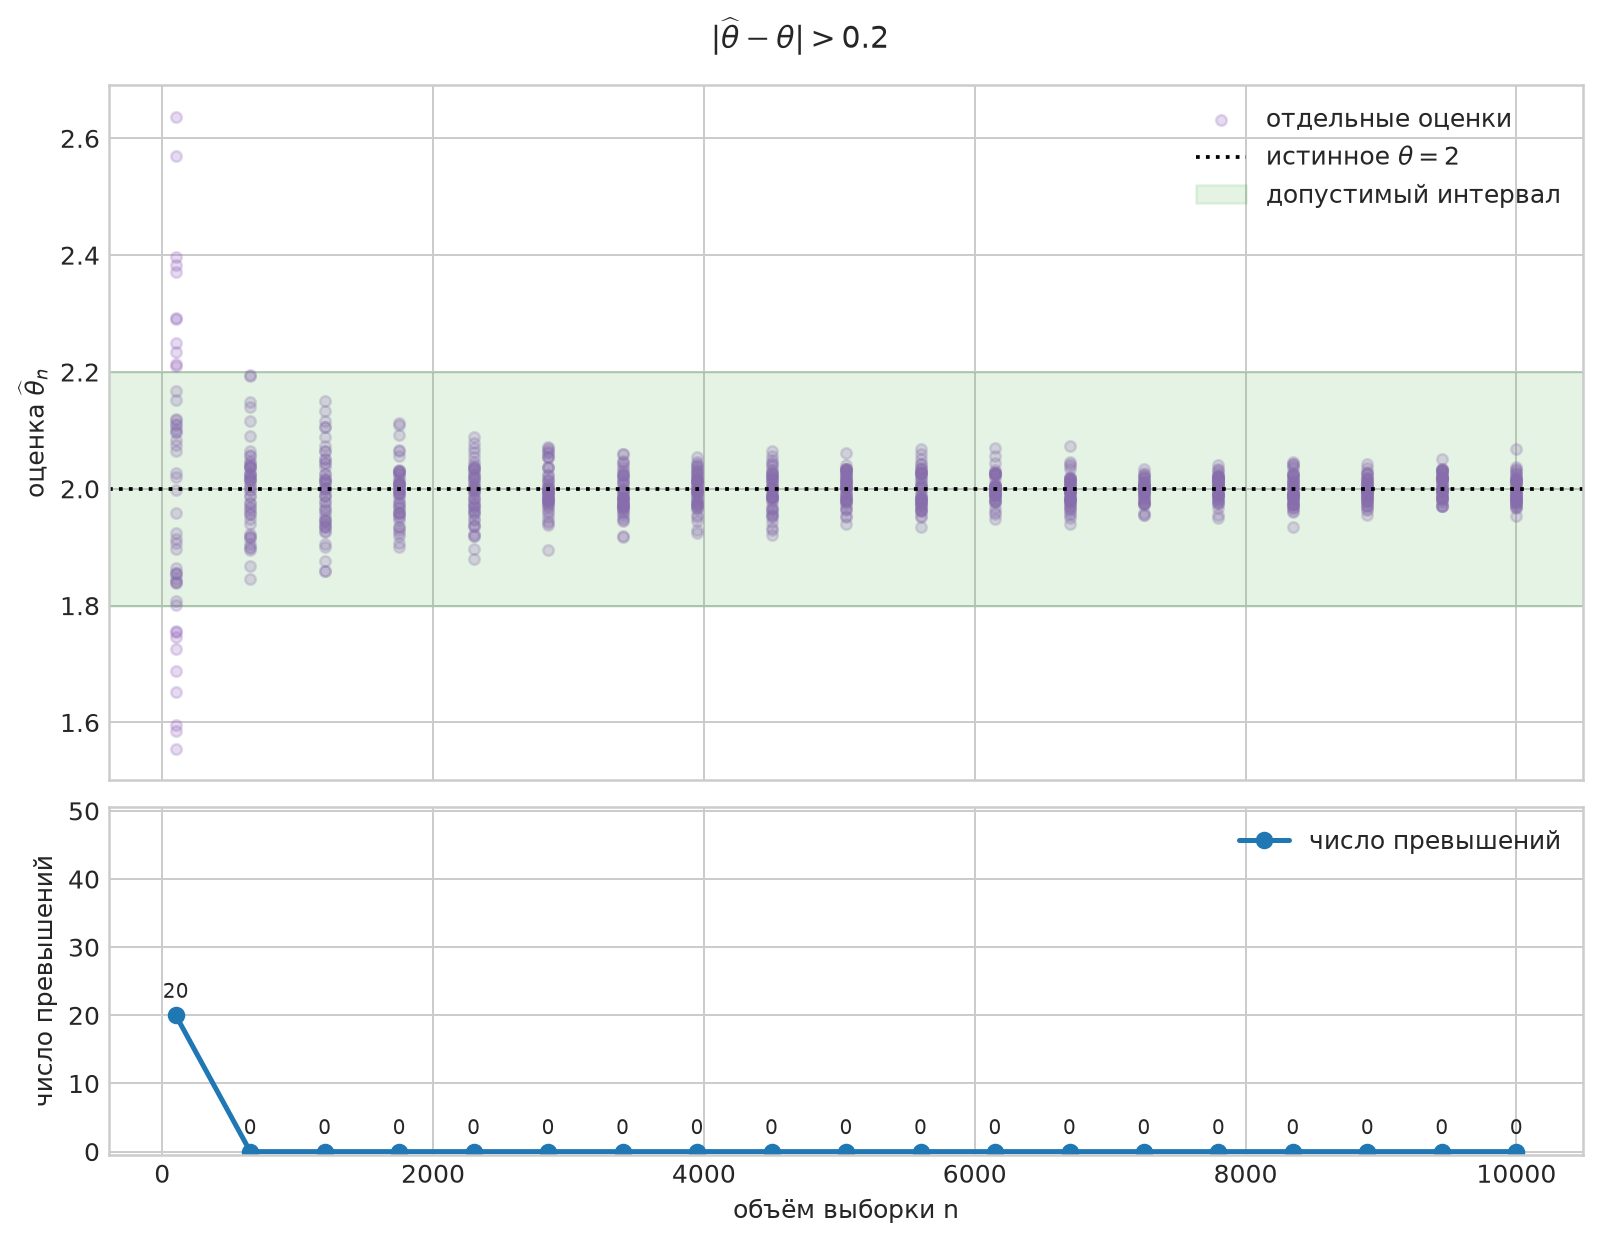

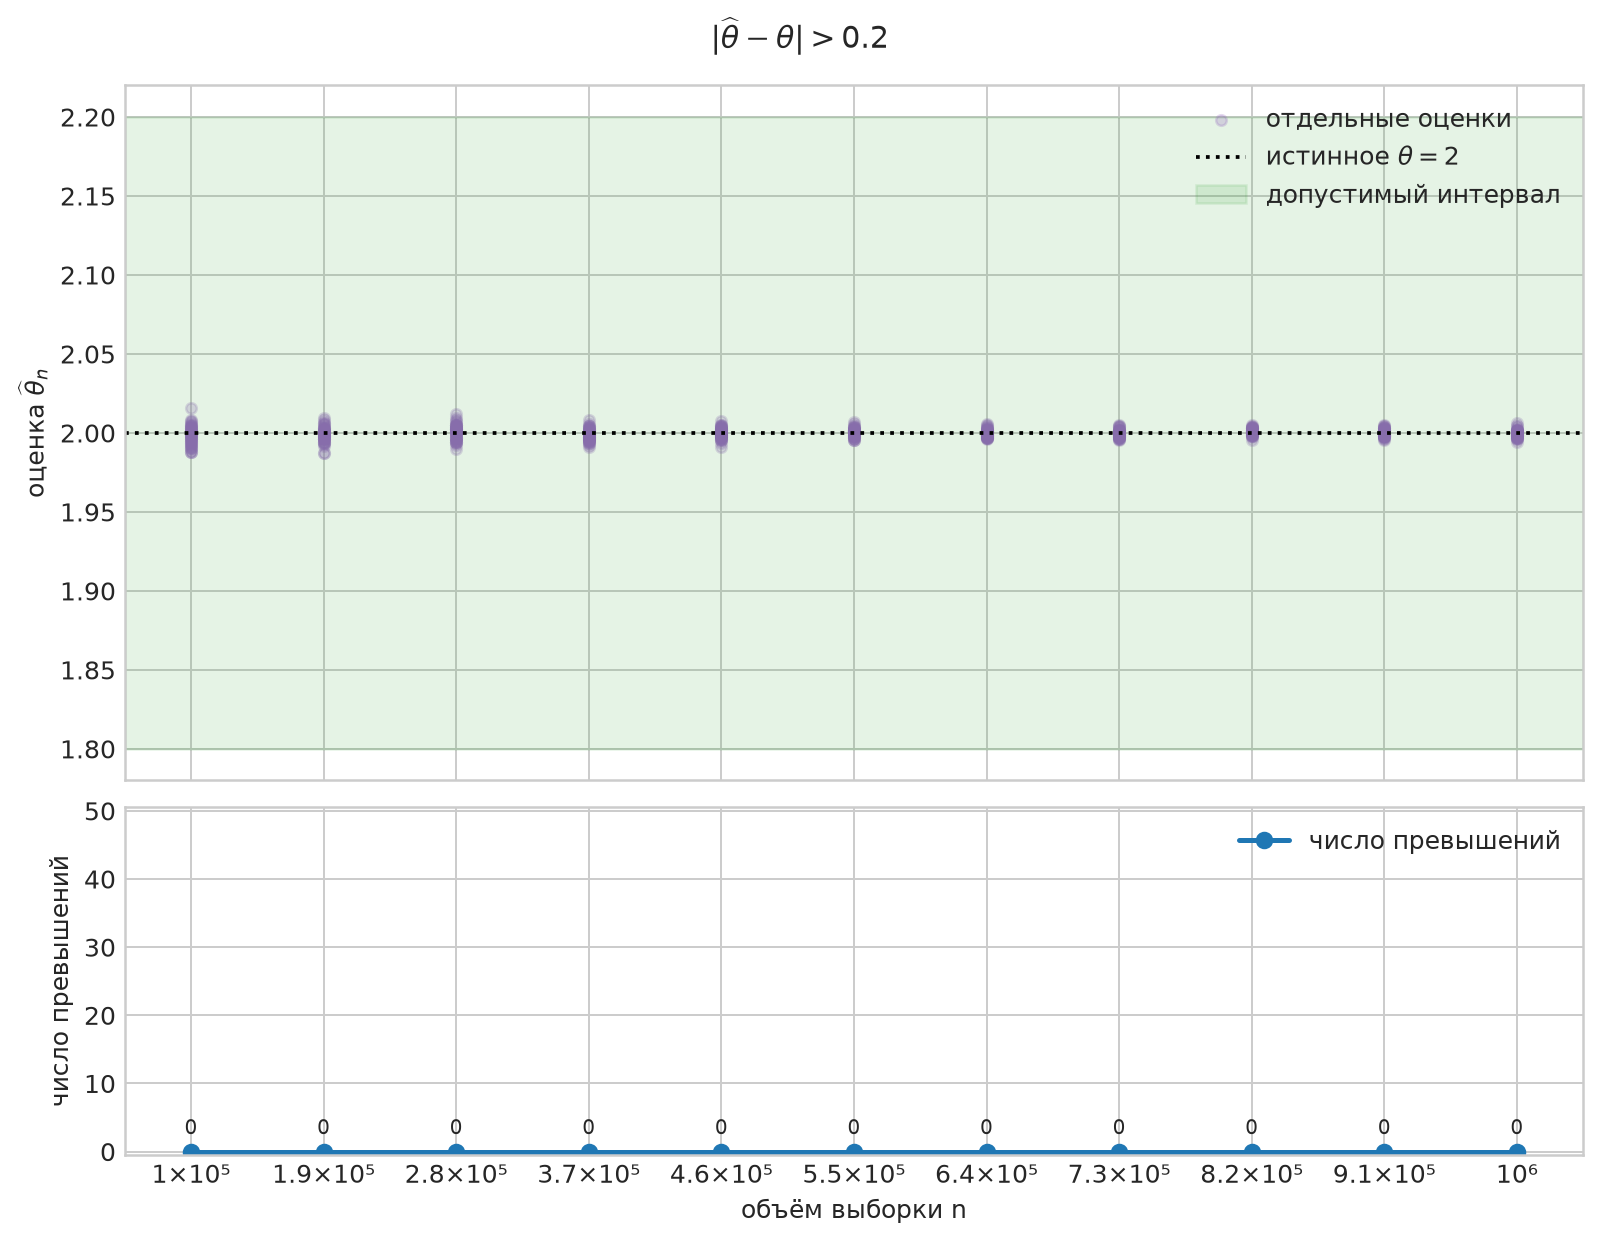

In [8]:
for current_experiment in experiments:
    threshold_image = save_threshold_exceedance_plot(
        current_experiment
    )
    display(Image(filename=str(threshold_image)))

### Мини-вывод

На каждой из трёх шкал число выходов за интервал $[1.8,2.2]$ уменьшается при росте $n$. На больших объёмах выборки оценки концентрируются около $\theta=2$, поэтому число превышений становится равным нулю или близким к нему.

## Выводы

Метод моментов дал оценку

$$\widehat\theta_n=\frac{\overline X}{1-\overline X}.$$

Для результатов повторного моделирования вычислены выборочные характеристики разности $\widehat\theta_n-\theta$: смещение, дисперсия, MSE и число превышений заданного порога.

Теоретические смещение, дисперсия и MSE получены точно через обратные моменты суммы $T_n=\sum_i(1-X_i)$. Одномерные интегралы $A_1$ и $A_2$ вычисляются численно для каждого $n$, поэтому на графиках используется точная теоретическая линия, а не асимптотическое разложение.

При увеличении $n$ оценки концентрируются около $\theta=2$, а смещение, дисперсия, MSE и число превышений порога уменьшаются. Это согласуется с доказанной состоятельностью оценки.